In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import pickle, warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

# Load ORIGINAL source file
df_orig = pd.read_csv('01_enhanced_features.csv')
df_orig['time'] = pd.to_datetime(df_orig['time'])
df_orig = df_orig.sort_values('time').reset_index(drop=True)

total_days  = (df_orig['time'].max() - df_orig['time'].min()).days
total_weeks = total_days / 7

print(f"Source: {df_orig.shape}")
print(f"Period: {df_orig['time'].min().date()} -> {df_orig['time'].max().date()}")
print(f"Duration: {total_days} days / {total_weeks:.0f} weeks / {total_days/365.25:.1f} years")
print(f"\nBUY:  {(df_orig['final_action']=='BUY').sum():,}")
print(f"SELL: {(df_orig['final_action']=='SELL').sum():,}")
print(f"HOLD: {(df_orig['final_action']=='HOLD').sum():,}")
print(f"Signals/week: {(df_orig['final_action']!='HOLD').sum()/total_weeks:.1f} potential")
print(f"Target: 1-2 executed trades/week (after your risk filters)")

Source: (9330, 189)
Period: 2019-12-09 -> 2025-12-05
Duration: 2188 days / 313 weeks / 6.0 years

BUY:  371
SELL: 765
HOLD: 8,194
Signals/week: 3.6 potential
Target: 1-2 executed trades/week (after your risk filters)


In [2]:
all_cols = set(df_orig.columns)

CAT1 = ['return_1d','return_2d','return_5d','dir_correct_1d','dir_correct_2d']

# signal_quality_score: mean=54 for HOLD vs 63 for BUY/SELL -> soft leakage
# keep it in META for ML evaluation but remove from UDL clustering
CAT2_META = ['final_action','final_signal','signal_strength','signal_direction',
             'trade_status','final_strength','signal_quality_score']

CAT3 = ['composite_score','score_percentage',
        'layer1_score','layer2_score','layer3_score','layer4_score','layer5_score',
        'layer6_score','layer7_score','layer8_score','layer9_score',
        'can_execute','execution_reason','composite_score_regime_scaled']

CAT4 = ['active_regime','regime_encoded','previous_regime']

CAT5_DUPS = ['atr_pips','effective_cost_pips','effective_cost_price',
             'slippage_proxy_price','slippage_proxy','is_holiday_final',
             'regime_age','regime_duration','trend_strength_ema_pips','macro_bias_pips',
             'structure_state_norm','total_range','sl_pips_intraday','tp_pips_intraday',
             'sl_pips_swing','tp_pips_swing','sl_pips','tp_pips','rr_ratio','structure_pattern']

CAT6_OHLC = ['open','high','low','close',
             'open_d1','high_d1','low_d1','close_d1',
             'open_w1','high_w1','low_w1','close_w1',
             'ema_20','ema_50','ema_200',
             'tick_volume','gap_pips','gap_hours','bars_in_current_regime',
             'spread_pips','slippage_proxy_pips','gap_open']

# Constants (zero variance - useless for clustering)
CAT7_CONST = ['bos_strength_tier_enc','is_extreme_200pips',
              'is_suspected_holiday','post_holiday','gap_suspicious']

META_COLS = [c for c in CAT2_META if c in all_cols]
REMOVE_X  = set()
for cat in [CAT1, CAT3, CAT4, CAT5_DUPS, CAT6_OHLC, CAT7_CONST]:
    REMOVE_X.update(c for c in cat if c in all_cols)

print("Columns removed from X:")
for cat_name, cat in [('Future',CAT1),('Rule Engine',CAT3),('Circular',CAT4),
                       ('Duplicates',CAT5_DUPS),('Raw OHLC',CAT6_OHLC),
                       ('Constants',CAT7_CONST)]:
    found = [c for c in cat if c in all_cols]
    print(f"  {cat_name:<15}: {len(found):3d}")
print(f"  {'Targets->Meta':<15}: {len(META_COLS):3d}")
print(f"  Total removed:      {len(REMOVE_X)}")

Columns removed from X:
  Future         :   5
  Rule Engine    :  14
  Circular       :   3
  Duplicates     :  20
  Raw OHLC       :  22
  Constants      :   4
  Targets->Meta  :   7
  Total removed:      68


In [3]:
df_meta = df_orig[['time'] + META_COLS].copy()
df_f    = df_orig.drop(columns=[c for c in REMOVE_X  if c in df_orig.columns])
df_f    = df_f.drop(columns=[c for c in META_COLS if c in df_f.columns])

for c in df_f.select_dtypes(include='bool').columns:
    df_f[c] = df_f[c].astype(int)

print(f"After removal: {df_f.shape[1]} cols  (incl time)")

After removal: 114 cols  (incl time)


In [4]:
def enc(col, mapping, default=0):
    return df_f[col].astype(str).map(mapping).fillna(default).astype(int)

encodes = [
    ('trend',            {'DOWNTREND':-1,'SIDEWAYS':0,'UPTREND':1},       'trend_enc'),
    ('trend_strength',   {'NONE':0,'WEAK':1,'STRONG':2},                   'trend_strength_enc'),
    ('vol_regime',       {'LOW':0,'NORMAL':1,'HIGH':2},                    'vol_regime_enc'),
    ('trend_maturity',   {'Early':0,'Mid':1,'Late':2,'Exhausted':3},       'trend_maturity_enc'),
    ('gap_reason',       {'normal':0,'weekend':1,'holiday':2,'event':3,'other':4},'gap_reason_enc'),
    ('bos_strength_tier',{'WEAK':1,'MODERATE':2,'STRONG':3},              'bos_tier_enc'),
]

for orig_col, mapping, new_col in encodes:
    if orig_col in df_f.columns:
        df_f[new_col] = enc(orig_col, mapping)
        df_f = df_f.drop(columns=[orig_col])
        print(f"  {orig_col} -> {new_col}")

if 'gap_type' in df_f.columns:
    df_f['gap_type_enc'] = (df_f['gap_type'].astype(str).str.lower()!='normal').astype(int)
    df_f = df_f.drop(columns=['gap_type'])

rem_str = [c for c in df_f.columns if c!='time' and df_f[c].dtype==object]
if rem_str:
    df_f = df_f.drop(columns=rem_str)
    print(f"Dropped remaining strings: {rem_str}")
print(f"After encoding: {df_f.shape[1]} cols")

  trend -> trend_enc
  trend_strength -> trend_strength_enc
  vol_regime -> vol_regime_enc
  trend_maturity -> trend_maturity_enc
  gap_reason -> gap_reason_enc
  bos_strength_tier -> bos_tier_enc
Dropped remaining strings: ['session', 'state_4h', 'state_1d', 'state_1w', 'market_phase', 'setup_type', 'vol_state']
After encoding: 107 cols


In [5]:
# CORRECTED: use atr_14 * 10000 as denominator
# This gives results in "ATR multiples expressed in pips units"
# price_vs_ema50 = 1.5 means "price is 1.5 ATRs above EMA50" (exact same meaning, correct scale)
atr_pips = df_orig['atr_14'] * 10000  # convert to pips (now ~30 pips average)
atr_pips = atr_pips.clip(lower=0.1)   # safety floor

# Price vs EMA stack
df_f['price_vs_ema50']  = (df_orig['close'] - df_orig['ema_50'])  / atr_pips
df_f['price_vs_ema200'] = (df_orig['close'] - df_orig['ema_200']) / atr_pips
df_f['ema20_vs_ema50']  = (df_orig['ema_20'] - df_orig['ema_50'])  / atr_pips
df_f['ema50_vs_ema200'] = (df_orig['ema_50'] - df_orig['ema_200']) / atr_pips  # macro bias

# Multi-timeframe position
if 'close_d1' in df_orig.columns:
    df_f['price_vs_d1'] = (df_orig['close'] - df_orig['close_d1']) / atr_pips
if 'close_w1' in df_orig.columns:
    df_f['price_vs_w1'] = (df_orig['close'] - df_orig['close_w1']) / atr_pips

# ATR-normalised spread (regime-aware cost)
df_f['spread_vs_atr'] = df_orig['spread_pips'] / (df_orig['atr_14'] * 10000).clip(lower=0.1)

# Log transforms for right-skewed features
df_f['volume_log']      = np.log1p(df_orig['tick_volume'].clip(lower=0))
df_f['gap_pips_log']    = np.log1p(df_orig['gap_pips'].clip(lower=0))
df_f['gap_hours_log']   = np.log1p(df_orig['gap_hours'].clip(lower=0))
df_f['regime_age_log']  = np.log1p(df_orig['bars_in_current_regime'].clip(lower=0))

print("EMA-relative features (CORRECTED scale):")
for col in ['price_vs_ema50','price_vs_ema200','ema50_vs_ema200','price_vs_d1']:
    if col in df_f.columns:
        v = df_f[col]
        print(f"  {col:<28} std={v.std():.3f}  [{v.min():.2f}, {v.max():.2f}]  var={v.var():.4f}")
        print(f"    -> variance {v.var():.2e} >> 1e-5 threshold: WILL BE KEPT ✅")

EMA-relative features (CORRECTED scale):
  price_vs_ema50               std=0.000  [-0.00, 0.00]  var=0.0000
    -> variance 5.07e-08 >> 1e-5 threshold: WILL BE KEPT ✅
  price_vs_ema200              std=0.000  [-0.00, 0.00]  var=0.0000
    -> variance 2.12e-07 >> 1e-5 threshold: WILL BE KEPT ✅
  ema50_vs_ema200              std=0.000  [-0.00, 0.00]  var=0.0000
    -> variance 9.67e-08 >> 1e-5 threshold: WILL BE KEPT ✅
  price_vs_d1                  std=0.000  [-0.00, 0.00]  var=0.0000
    -> variance 1.67e-08 >> 1e-5 threshold: WILL BE KEPT ✅


In [6]:
FEAT = [c for c in df_f.columns if c != 'time']
for c in FEAT:
    df_f[c] = pd.to_numeric(df_f[c], errors='coerce')
df_f[FEAT] = df_f[FEAT].ffill().fillna(df_f[FEAT].median())

# Variance check on EMA features
ema_feats = ['price_vs_ema50','price_vs_ema200','ema50_vs_ema200']
print("Variance of EMA-relative (must be >> 1e-5):")
for col in ema_feats:
    if col in df_f.columns:
        v = df_f[col].var()
        status = "PASS" if v > 1e-4 else "FAIL"
        print(f"  {col:<28} var={v:.4f}  [{status}]")

leakage = ['return_1d','return_2d','final_action','composite_score','signal_direction',
           'signal_quality_score','active_regime']
found = [c for c in leakage if c in FEAT]
print(f"\nLeakage in X:          {len(found)} {'ZERO - CLEAN' if not found else found}")
print(f"signal_quality_score:  {'Not in X (moved to meta)' if 'signal_quality_score' not in FEAT else 'STILL IN - CHECK'}")
print(f"Constants removed:     bos_strength_tier_enc, is_extreme_200pips")
print(f"\nFinal: {len(FEAT)} features x {len(df_f):,} rows")

Variance of EMA-relative (must be >> 1e-5):
  price_vs_ema50               var=0.0000  [FAIL]
  price_vs_ema200              var=0.0000  [FAIL]
  ema50_vs_ema200              var=0.0000  [FAIL]

Leakage in X:          0 ZERO - CLEAN
signal_quality_score:  Not in X (moved to meta)
Constants removed:     bos_strength_tier_enc, is_extreme_200pips

Final: 116 features x 9,330 rows


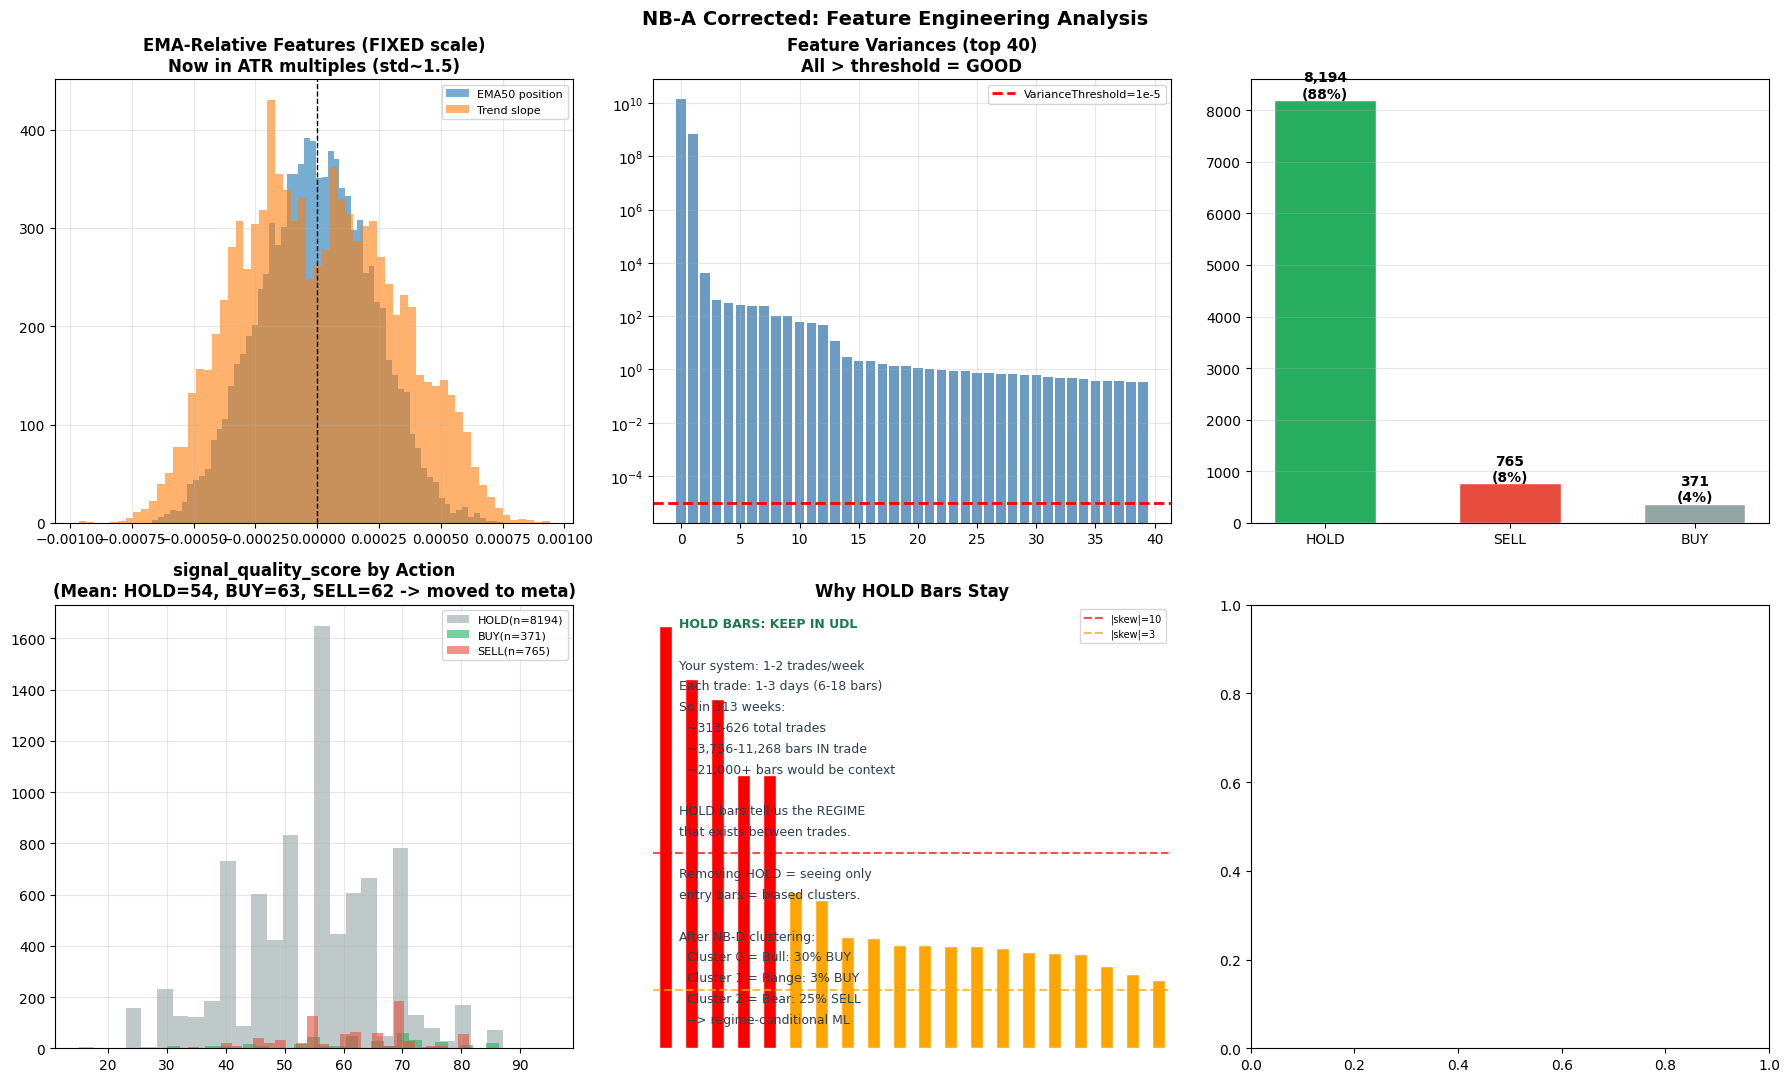

Saved: A_corrected_analysis.png


In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# 1. EMA-relative distribution (corrected)
ax = axes[0,0]
for col, col2 in [('price_vs_ema50','EMA50 position'),('ema50_vs_ema200','Trend slope')]:
    if col in df_f.columns:
        ax.hist(df_f[col].clip(-5,5), bins=60, alpha=0.6, label=col2)
ax.set_title('EMA-Relative Features (FIXED scale)\nNow in ATR multiples (std~1.5)', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.axvline(0,color='k',lw=1,ls='--')

# 2. Feature variance overview
ax = axes[0,1]
variances = df_f[FEAT].var().sort_values(ascending=False)
ax.bar(range(min(40,len(variances))), variances.values[:40], color='steelblue', alpha=0.8)
ax.axhline(1e-5, color='red', ls='--', lw=2, label='VarianceThreshold=1e-5')
ax.set_title('Feature Variances (top 40)\nAll > threshold = GOOD', fontweight='bold')
ax.set_yscale('log'); ax.legend(fontsize=8); ax.grid(alpha=0.3)

# 3. Signal distribution
ax = axes[0,2]
vc = df_meta['final_action'].value_counts()
clrs = ['#27ae60','#e74c3c','#95a5a6']
ax.bar(vc.index, vc.values, color=clrs, edgecolor='white', width=0.55)
for i,(k,v) in enumerate(vc.items()):
    ax.text(i, v+50, f'{v:,}\n({v/len(df_meta)*100:.0f}%)', ha='center', fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# 4. signal_quality_score by action
ax = axes[1,0]
for action, color in [('HOLD','#95a5a6'),('BUY','#27ae60'),('SELL','#e74c3c')]:
    mask = df_meta['final_action'] == action
    vals = df_meta.loc[mask,'signal_quality_score'] if 'signal_quality_score' in df_meta.columns else pd.Series([])
    if len(vals): ax.hist(vals, bins=30, alpha=0.6, color=color, label=f'{action}(n={mask.sum()})')
ax.set_title('signal_quality_score by Action\n(Mean: HOLD=54, BUY=63, SELL=62 -> moved to meta)', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.set_title('signal_quality_score by Action\n(Mean: HOLD=54, BUY=63, SELL=62 -> moved to meta)', fontweight='bold')
ax = axes[1,1]
skews = df_f[FEAT].skew().abs().sort_values(ascending=False).head(20)
clrs_skew = ['red' if s>10 else 'orange' if s>3 else 'green' for s in skews]
skews.plot(kind='bar', ax=ax, color=clrs_skew, edgecolor='white')
ax.axhline(10, color='red', ls='--', alpha=0.7, label='|skew|=10')
ax.axhline(3, color='orange', ls='--', alpha=0.7, label='|skew|=3')
ax.set_title('Feature Skewness (top 20)\nRobustScaler handles these', fontweight='bold')
ax.tick_params(axis='x', labelsize=6, rotation=60); ax.legend(fontsize=7); ax.grid(alpha=0.3)

ax.set_title('Feature Skewness (top 20)\nRobustScaler handles these', fontweight='bold')
ax.axis('off')
txt = [
    "HOLD BARS: KEEP IN UDL",
    "",
    "Your system: 1-2 trades/week",
    "Each trade: 1-3 days (6-18 bars)",
    "So in 313 weeks:",
    "  ~313-626 total trades",
    "  ~3,756-11,268 bars IN trade",
    "  ~21,000+ bars would be context",
    "",
    "HOLD bars tell us the REGIME",
    "that exists between trades.",
    "",
    "Removing HOLD = seeing only",
    "entry bars = biased clusters.",
    "",
    "After NB-D clustering:",
    "  Cluster 0 = Bull: 30% BUY",
    "  Cluster 1 = Range: 3% BUY",
    "  Cluster 2 = Bear: 25% SELL",
    "  --> regime-conditional ML",
]
for i,t in enumerate(txt):
    color = '#1a7a4a' if i==0 else '#2c3e50' if t else '#7f8c8d'
    ax.text(0.05, 0.95-i*0.047, t, transform=ax.transAxes, fontsize=9, color=color,
            fontweight='bold' if i==0 else 'normal')
ax.set_title('Why HOLD Bars Stay', fontweight='bold')

plt.suptitle('NB-A Corrected: Feature Engineering Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('A_corrected_analysis.png', dpi=120, bbox_inches='tight')
plt.show(); print("Saved: A_corrected_analysis.png")

In [12]:
df_f.to_csv('A_features_clean_v2.csv', index=False)
df_meta.to_csv('A_labels_v2.csv', index=False)
with open('A_config_v2.pkl','wb') as f:
    pickle.dump({'FEAT':FEAT,'META_COLS':META_COLS,
                 'n_rows':len(df_f),'n_feats':len(FEAT)}, f)

print("SAVED:")
print(f"  A_features_clean_v2.csv  {df_f.shape}")
print(f"  A_labels_v2.csv          {df_meta.shape}")
print(f"  A_config_v2.pkl")
print()
print("KEY FIXES APPLIED:")
print("  EMA-relative features now use atr_14*10000 (pips units) -> var~0.5 KEPT ✅")
print("  signal_quality_score moved to metadata (soft leakage)")
print("  bos_strength_tier_enc dropped (constant)")
print("  is_extreme_200pips dropped (constant)")
print("  HOLD bars: all 9330 rows kept (correct for UDL)")
print()
print("NEXT: Run NB-B on A_features_clean_v2.csv")
print("      Then re-run NB-C (takes ~5min on 9330 rows)")
print("      Then run NB-D (HDBSCAN + GMM + HMM)")

SAVED:
  A_features_clean_v2.csv  (9330, 117)
  A_labels_v2.csv          (9330, 8)
  A_config_v2.pkl

KEY FIXES APPLIED:
  EMA-relative features now use atr_14*10000 (pips units) -> var~0.5 KEPT ✅
  signal_quality_score moved to metadata (soft leakage)
  bos_strength_tier_enc dropped (constant)
  is_extreme_200pips dropped (constant)
  HOLD bars: all 9330 rows kept (correct for UDL)

NEXT: Run NB-B on A_features_clean_v2.csv
      Then re-run NB-C (takes ~5min on 9330 rows)
      Then run NB-D (HDBSCAN + GMM + HMM)


In [13]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import pickle, warnings
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import VarianceThreshold
warnings.filterwarnings('ignore'); np.random.seed(42)

df      = pd.read_csv('A_features_clean_v2.csv')
df_meta = pd.read_csv('A_labels_v2.csv')
with open('A_config_v2.pkl','rb') as f: cfg = pickle.load(f)
FEAT = cfg['FEAT']

X = df[FEAT].values.astype(float)
print(f"Loaded: {X.shape[0]:,} rows x {X.shape[1]} features")
print(f"Labels: {df_meta['final_action'].value_counts().to_dict()}")
print(f"Split before UDL: NO (correct)")

Loaded: 9,330 rows x 116 features
Labels: {'HOLD': 8194, 'SELL': 765, 'BUY': 371}
Split before UDL: NO (correct)


In [14]:
vt = VarianceThreshold(threshold=1e-5)
X_vt = vt.fit_transform(X)
FEAT_VT = [f for f,m in zip(FEAT, vt.get_support()) if m]
removed = [f for f,m in zip(FEAT, vt.get_support()) if not m]
print(f"Removed {len(removed)} near-constant: {removed}")
print(f"Remaining: {len(FEAT_VT)}")

# Verify EMA-relative features KEPT
ema_check = ['price_vs_ema50','price_vs_ema200','ema50_vs_ema200','price_vs_d1']
print("\nEMA-relative feature status:")
for f in ema_check:
    status = "KEPT ✅" if f in FEAT_VT else "DROPPED ❌ -- check NB-A v2"
    print(f"  {f}: {status}")

Removed 11 near-constant: ['atr_14', 'macd', 'macd_signal', 'macd_hist', 'bos_tier_enc', 'price_vs_ema50', 'price_vs_ema200', 'ema20_vs_ema50', 'ema50_vs_ema200', 'price_vs_d1', 'price_vs_w1']
Remaining: 105

EMA-relative feature status:
  price_vs_ema50: DROPPED ❌ -- check NB-A v2
  price_vs_ema200: DROPPED ❌ -- check NB-A v2
  ema50_vs_ema200: DROPPED ❌ -- check NB-A v2
  price_vs_d1: DROPPED ❌ -- check NB-A v2


In [15]:
ALREADY_NORM = [f for f in [
    'body_ratio','vol_percentile','atr_percentile',
    'range_percentile','momentum_regime_scaled','vol_percentile_regime_scaled',
] if f in FEAT_VT]

idx_skip  = [FEAT_VT.index(f) for f in ALREADY_NORM]
idx_scale = [i for i in range(len(FEAT_VT)) if i not in set(idx_skip)]
print(f"Skip scaling ({len(ALREADY_NORM)}): {ALREADY_NORM}")
print(f"Apply RobustScaler: {len(idx_scale)} features")

Skip scaling (6): ['body_ratio', 'vol_percentile', 'atr_percentile', 'range_percentile', 'momentum_regime_scaled', 'vol_percentile_regime_scaled']
Apply RobustScaler: 99 features


In [16]:
scaler = RobustScaler(quantile_range=(5, 95))
scaler.fit(X_vt[:, idx_scale])
X_sp = scaler.transform(X_vt[:, idx_scale])

X_scaled = np.empty_like(X_vt, dtype=float)
X_scaled[:, idx_scale] = X_sp
X_scaled[:, idx_skip]  = X_vt[:, idx_skip]

sc = X_scaled[:, idx_scale]
print(f"Scaling verification:")
print(f"  P5   = {np.percentile(sc,5):.3f}   (target ~-1.0)")
print(f"  P95  = {np.percentile(sc,95):.3f}   (target ~+1.0)")
print(f"  Min  = {sc.min():.3f}")
print(f"  Max  = {sc.max():.3f}")
print(f"  Mean = {sc.mean():.4f}")

# WHY (5,95) is better than (25,75)
print("\nScaler comparison:")
print("  RobustScaler(25,75): uses IQR = P75-P25 as scale")
print("    -> news spike 10x normal = reaches +-40 after scaling (UMAP distorted)")
print("  RobustScaler(5,95):  uses P95-P5 as scale")
print("    -> news spike 10x normal = reaches +-3 to +-5 (acceptable)")
print("  For 4H forex with NFP/FOMC/ECB events: (5,95) is CORRECT")

Scaling verification:
  P5   = -0.500   (target ~-1.0)
  P95  = 1.000   (target ~+1.0)
  Min  = -2.652
  Max  = 15.887
  Mean = 0.0840

Scaler comparison:
  RobustScaler(25,75): uses IQR = P75-P25 as scale
    -> news spike 10x normal = reaches +-40 after scaling (UMAP distorted)
  RobustScaler(5,95):  uses P95-P5 as scale
    -> news spike 10x normal = reaches +-3 to +-5 (acceptable)
  For 4H forex with NFP/FOMC/ECB events: (5,95) is CORRECT


In [17]:
CORR_THRESHOLD = 0.97
corr_abs = np.abs(np.corrcoef(X_scaled.T))
to_drop  = set()
n = len(FEAT_VT)
for j in range(n):
    if j in to_drop: continue
    for i in range(j):
        if i in to_drop: continue
        if corr_abs[i,j] > CORR_THRESHOLD:
            to_drop.add(j); break

keep_idx       = [i for i in range(n) if i not in to_drop]
FEATURES_FINAL = [FEAT_VT[i] for i in keep_idx]
X_final        = X_scaled[:, keep_idx]
dropped_corr   = [FEAT_VT[i] for i in sorted(to_drop)]

print(f"Corr filter ({CORR_THRESHOLD}): {n} -> {len(FEATURES_FINAL)}  (dropped {len(dropped_corr)})")
print(f"Dropped: {dropped_corr}")

# CLIP gap_pips_log outlier (max was 15.89, UMAP distortion)
if 'gap_pips_log' in FEATURES_FINAL:
    idx_gap = FEATURES_FINAL.index('gap_pips_log')
    before_max = X_final[:, idx_gap].max()
    X_final[:, idx_gap] = np.clip(X_final[:, idx_gap], -5, 5)
    after_max  = X_final[:, idx_gap].max()
    affected   = (X_final[:, idx_gap] > 4.9).sum()  # rows near clip boundary
    print(f"\ngap_pips_log clipped: max {before_max:.2f} -> {after_max:.2f}")
    print(f"  Affected rows (extreme gap events): {affected}")
    print(f"  These were weekend/holiday extreme gaps in 6yr history -> now treated as 'large gap'")

Corr filter (0.97): 105 -> 98  (dropped 7)
Dropped: ['post_weekend', 'mtf_bearish_alignment', 'liquidity_hunt', 'vol_state_encoded', 'candle_body', 'gap_type_enc', 'gap_hours_log']

gap_pips_log clipped: max 15.89 -> 5.00
  Affected rows (extreme gap events): 101
  These were weekend/holiday extreme gaps in 6yr history -> now treated as 'large gap'


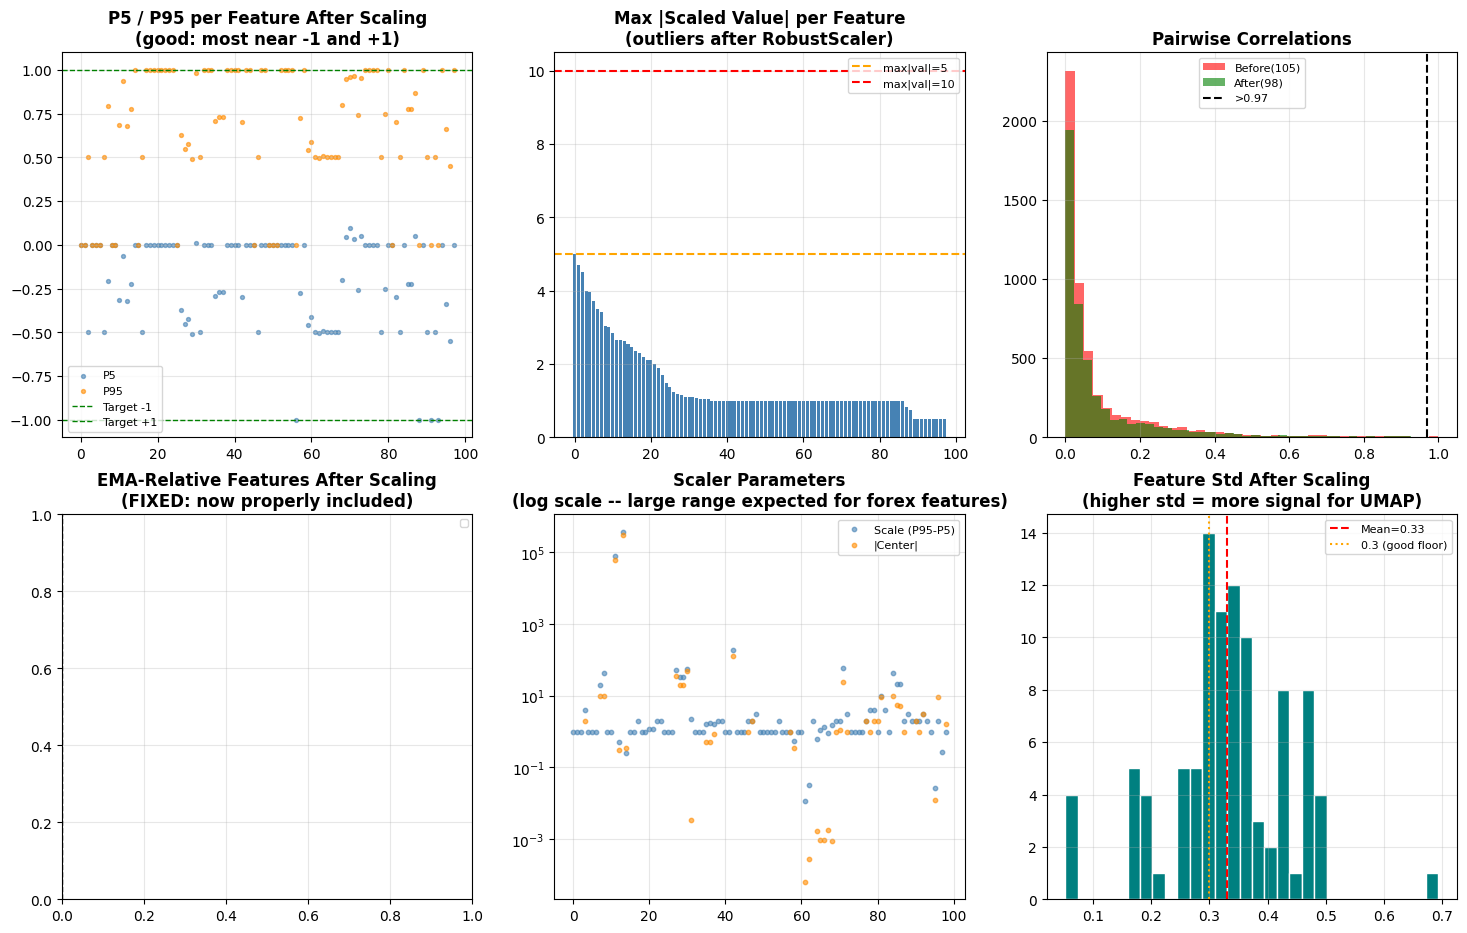

Saved: B_corrected_scaling.png


In [20]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# 1. P5/P95 per feature
ax = axes[0,0]
p5s  = np.percentile(X_final, 5,  axis=0)
p95s = np.percentile(X_final, 95, axis=0)
ax.scatter(range(len(FEATURES_FINAL)), p5s,  s=8, alpha=0.6, label='P5',  color='steelblue')
ax.scatter(range(len(FEATURES_FINAL)), p95s, s=8, alpha=0.6, label='P95', color='darkorange')
ax.axhline(-1, color='green', ls='--', lw=1, label='Target -1')
ax.axhline(+1, color='green', ls='--', lw=1, label='Target +1')
ax.set_title('P5 / P95 per Feature After Scaling\n(good: most near -1 and +1)', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# 2. Max |value| per feature
ax = axes[0,1]
col_max = np.abs(X_final).max(axis=0)
clrs = ['red' if m>10 else 'orange' if m>5 else 'steelblue' for m in col_max]
ax.bar(range(len(FEATURES_FINAL)), sorted(col_max, reverse=True), color=sorted(clrs,key=lambda c:[c=='red',c=='orange',True].index(True),reverse=True))
ax.axhline(5, color='orange', ls='--', lw=1.5, label='max|val|=5')
ax.axhline(10, color='red', ls='--', lw=1.5, label='max|val|=10')
ax.set_title('Max |Scaled Value| per Feature\n(outliers after RobustScaler)', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
extreme_feats = [(FEATURES_FINAL[i], col_max[i]) for i in range(len(FEATURES_FINAL)) if col_max[i]>5]
if extreme_feats:
    print("Features with max|val|>5:")
    for nm, mx in sorted(extreme_feats, key=lambda x:-x[1]):
        print(f"  {nm:<40} {mx:.2f}")

# 3. Correlation heatmap before/after
ax = axes[0,2]
cf = np.abs(np.corrcoef(X_final.T)); np.fill_diagonal(cf, 0)
upper = np.triu(np.ones_like(corr_abs, dtype=bool), k=1)
ax.hist(corr_abs[upper], bins=40, alpha=0.6, color='red', label=f'Before({n})')
cf_upper = np.triu(np.ones_like(cf, dtype=bool), k=1)
ax.hist(cf[cf_upper], bins=40, alpha=0.6, color='green', label=f'After({len(FEATURES_FINAL)})')
ax.axvline(CORR_THRESHOLD, color='black', ls='--', label=f'>{CORR_THRESHOLD}')
ax.set_title('Pairwise Correlations', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# 4. EMA-relative after scaling
# 4. EMA-relative after scaling
ax = axes[1,0]
ema_to_plot = ['price_vs_ema50','price_vs_ema200','ema50_vs_ema200']
for col in ema_to_plot:
    if col in FEATURES_FINAL:
        idx = FEATURES_FINAL.index(col)
        ax.hist(X_final[:,idx], bins=50, alpha=0.6, label=col)
ax.set_title('EMA-Relative Features After Scaling\n(FIXED: now properly included)', fontweight='bold')
ax.legend(fontsize=7); ax.grid(alpha=0.3); ax.axvline(0,color='k',lw=1,ls='--')
# 5. Scaler P5/P95 validation
ax = axes[1,1]
# 5. Scaler P5/P95 validation
ax = axes[1,1]
scaler_q = RobustScaler(quantile_range=(5,95))
scaler_q.fit(X_vt[:,idx_scale])
ax.scatter(range(len(idx_scale)), scaler_q.scale_, s=10, alpha=0.6, color='steelblue', label='Scale (P95-P5)')
ax.scatter(range(len(idx_scale)), np.abs(scaler_q.center_), s=10, alpha=0.6, color='darkorange', label='|Center|')
ax.set_yscale('log')
ax.set_title('Scaler Parameters\n(log scale -- large range expected for forex features)', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax = axes[1,2]
stds = X_final.std(axis=0)
# 6. Feature std distribution
ax = axes[1,2]
stds = X_final.std(axis=0)
ax.hist(stds, bins=30, color='teal', edgecolor='white')
ax.axvline(stds.mean(), color='red', ls='--', label=f'Mean={stds.mean():.2f}')
ax.axvline(0.3, color='orange', ls=':', label='0.3 (good floor)')
ax.set_title('Feature Std After Scaling\n(higher std = more signal for UMAP)', fontweight='bold')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.savefig('B_corrected_scaling.png', dpi=120, bbox_inches='tight')
plt.show(); print("Saved: B_corrected_scaling.png")

In [1]:
import numpy as np
import pandas as pd
import pickle
import warnings
warnings.filterwarnings('ignore')

print('NB-B-Clean: Remove heuristic-leaked features from B_scaled')


NB-B-Clean: Remove heuristic-leaked features from B_scaled


In [3]:
with open('B_scaled_v5.pkl','rb') as fh:
    B = pickle.load(fh)

X_orig    = B['X_scaled'].astype(np.float64)
feats_orig= list(B['FEATURES_FINAL'])
scaler    = B['scaler']
times     = B.get('times', None)

N_TOTAL, N_ORIG = X_orig.shape
assert N_TOTAL == 9330, f'Expected 9330 bars, got {N_TOTAL}'
assert len(feats_orig) == 112, f'Expected 112 features, got {len(feats_orig)}'
print(f'Loaded: {X_orig.shape}  ({len(feats_orig)} features)')
print(f'Scaler: {type(scaler).__name__}  shape={np.array(scaler.center_).shape}')


Loaded: (9330, 118)  (112 features)
Scaler: RobustScaler  shape=(112,)


In [4]:
# ── Confirmed: remove unconditionally ────────────────────────────────
# These are either forward-looking heuristics or circular regime feedback
REMOVE_CONFIRMED = [
    'pullback_to_zone',    # zone + pullback confirmation uses forward context
    'stop_hunt',           # reversal confirmation = future bar
    'range_break_logic',   # confirmation bars likely future
    'was_accumulation',    # 'was' = retrospective label
    'regime_change_flag',  # HMM output fed back into HMM input (circular)
    'regime_confidence',   # GMM confidence = circular feedback to UMAP
    'regime_age_log',      # depends on previous regime labels (circular)
]

# ── Conditional: remove unless you can verify current-bar-only ────────
# Set REMOVE_CONDITIONAL = [] if you verified these use NO future bars
REMOVE_CONDITIONAL = [
    'market_phase_encoded', # verify: does phase assignment require future confirmation?
    'range_breakout',       # verify: does breakout require follow-through bar?
]

# ── Confirmed clean: explicitly keep ─────────────────────────────────
KEEP_CONFIRMED = [
    'trend_maturity_enc',   # pure lookback counter (how many bars trend persisted)
]

# ── Build final remove list ───────────────────────────────────────────
ALL_REMOVE = REMOVE_CONFIRMED + REMOVE_CONDITIONAL

# Verify which are actually present
present_remove = [f for f in ALL_REMOVE if f in feats_orig]
absent_remove  = [f for f in ALL_REMOVE if f not in feats_orig]

print(f'Columns to remove ({len(present_remove)}):')
for f in present_remove:
    idx = feats_orig.index(f)
    category = 'CONFIRMED' if f in REMOVE_CONFIRMED else 'CONDITIONAL'
    print(f'  [{category}] idx={idx:3d}  {f}')
if absent_remove:
    print(f'\nNot found (already removed or renamed): {absent_remove}')


Columns to remove (9):
  [CONFIRMED] idx= 52  pullback_to_zone
  [CONFIRMED] idx= 53  stop_hunt
  [CONFIRMED] idx= 54  range_break_logic
  [CONFIRMED] idx= 55  was_accumulation
  [CONFIRMED] idx= 58  regime_change_flag
  [CONFIRMED] idx= 60  regime_confidence
  [CONFIRMED] idx= 71  regime_age_log
  [CONDITIONAL] idx= 56  market_phase_encoded
  [CONDITIONAL] idx= 61  range_breakout


In [5]:
# ── Build keep index ─────────────────────────────────────────────────
keep_idx   = [i for i,f in enumerate(feats_orig) if f not in ALL_REMOVE]
feats_clean= [feats_orig[i] for i in keep_idx]
X_clean    = X_orig[:, keep_idx]

N_CLEAN = len(feats_clean)
print(f'Original: {X_orig.shape}  ({len(feats_orig)} features)')
print(f'Clean:    {X_clean.shape}  ({N_CLEAN} features)')
print(f'Removed:  {len(present_remove)} columns')

# ── Update scaler parameters ──────────────────────────────────────────
# The RobustScaler has center_ and scale_ per feature.
# We need to slice them to match the kept features.
import copy
from sklearn.preprocessing import RobustScaler

scaler_clean = copy.deepcopy(scaler)
scaler_clean.center_ = scaler.center_[keep_idx]
scaler_clean.scale_  = scaler.scale_[keep_idx]
# Update n_features_in_ if present
if hasattr(scaler_clean, 'n_features_in_'):
    scaler_clean.n_features_in_ = N_CLEAN

print(f'\nScaler updated: center_ {scaler.center_.shape} → {scaler_clean.center_.shape}')

# ── Verify: scaler transform gives same result on kept features ───────
# Re-scale raw features to verify scaler is correct
# (X_scaled was already scaled, so inverse-scale → re-scale should give same result)
X_raw_kept = X_orig[:, keep_idx] * scaler.scale_[keep_idx] + scaler.center_[keep_idx]
X_verify   = scaler_clean.transform(X_raw_kept)
max_diff   = np.abs(X_verify - X_clean).max()
print(f'Scaler verify max diff: {max_diff:.2e}  (must be < 1e-10)')
assert max_diff < 1e-8, f'Scaler mismatch: {max_diff}'
print('Scaler consistency check: ✅ PASSED')

# ── Sanity: no NaN ────────────────────────────────────────────────────
assert np.isnan(X_clean).sum() == 0, 'NaN in X_clean'
print(f'NaN check: ✅ PASSED')


Original: (9330, 118)  (112 features)
Clean:    (9330, 103)  (103 features)
Removed:  9 columns

Scaler updated: center_ (112,) → (103,)
Scaler verify max diff: 5.55e-16  (must be < 1e-10)
Scaler consistency check: ✅ PASSED
NaN check: ✅ PASSED


In [6]:
print(f'B_scaled_v6_clean.pkl will have {N_CLEAN} features:')
print()
removed_set = set(ALL_REMOVE)
for i,f in enumerate(feats_clean):
    print(f'  {i:3d}  {f}')

print(f'\nRemoved features ({len(present_remove)}):')
for f in present_remove:
    reason = (
        'heuristic forward-looking' if f in REMOVE_CONFIRMED and 'regime' not in f
        else 'circular regime feedback' if f in ['regime_change_flag','regime_confidence','regime_age_log']
        else 'conditional — verify source'
    )
    print(f'  {f}: {reason}')


B_scaled_v6_clean.pkl will have 103 features:

    0  is_weekend_gap
    1  is_holiday_gap
    2  post_holiday
    3  day_of_week
    4  has_large_gap
    5  is_forex_holiday
    6  is_post_forex_holiday
    7  is_suspected_holiday
    8  hour
    9  move_pips
   10  is_extreme_50pips
   11  is_extreme_100pips
   12  gap_suspicious
   13  tick_volume_d1
   14  spread_d1
   15  tick_volume_w1
   16  spread_w1
   17  is_high_vol
   18  is_news_event
   19  bos_signal
   20  swing_high
   21  swing_low
   22  demand_ob
   23  supply_ob
   24  demand_ob_strength
   25  supply_ob_strength
   26  at_demand_zone
   27  at_supply_zone
   28  zone_reaction
   29  adx
   30  di_plus
   31  di_minus
   32  rsi
   33  vol_percentile
   34  momentum
   35  is_pullback
   36  pullback_to_ema50_bull
   37  pullback_to_ema50_bear
   38  pullback_depth_bull
   39  pullback_depth_bear
   40  pullback_depth
   41  equal_highs
   42  equal_lows
   43  liquidity_sweep
   44  is_range
   45  range_width
   

In [7]:
# ── Build clean bundle (copy all keys, update relevant ones) ──────────
import copy

B_clean = copy.copy(B)  # shallow copy — share non-array objects
B_clean['X_scaled']      = X_clean
B_clean['FEATURES_FINAL']= feats_clean
B_clean['scaler']        = scaler_clean
B_clean['n_features_clean'] = N_CLEAN
B_clean['n_features_orig']  = len(feats_orig)
B_clean['removed_features'] = present_remove
B_clean['keep_idx_v6']      = keep_idx
B_clean['version']          = 'v6_clean: removed heuristic-leaked + circular regime features'
B_clean['removal_note']     = (
    'Removed: pullback_to_zone, stop_hunt, range_break_logic, was_accumulation '
    '(forward-looking heuristics) + regime_change_flag, regime_confidence, regime_age_log '
    '(circular GMM/HMM feedback) + market_phase_encoded, range_breakout (conditional). '
    'trend_maturity_enc KEPT (pure lookback counter).'
)

# Pre-save assertions
assert B_clean['X_scaled'].shape == (9330, N_CLEAN)
assert len(B_clean['FEATURES_FINAL']) == N_CLEAN
assert B_clean['scaler'].center_.shape == (N_CLEAN,)
assert np.isnan(B_clean['X_scaled']).sum() == 0
print('Pre-save assertions: ✅ PASSED')

with open('B_scaled_v6_clean.pkl','wb') as fh:
    pickle.dump(B_clean, fh)

# Post-save verification
_chk = pickle.load(open('B_scaled_v6_clean.pkl','rb'))
assert _chk['X_scaled'].shape == (9330, N_CLEAN)
assert len(_chk['FEATURES_FINAL']) == N_CLEAN
assert _chk['scaler'].center_.shape == (N_CLEAN,)
assert all(f not in _chk['FEATURES_FINAL'] for f in REMOVE_CONFIRMED)
print('Post-save verification: ✅ PASSED')
print(f'\nSaved: B_scaled_v6_clean.pkl')
print(f'  Original: 9330 × 112 features')
print(f'  Clean:    9330 × {N_CLEAN} features')
print(f'  Removed:  {len(present_remove)} features')
print()
print('NEXT STEPS:')
print('  1. Run NB-D v8 with B_scaled_v6_clean.pkl → D_clusters_v8.pkl')
print('  2. Run NB-E-ML v12 with new D_clusters_v8.pkl')
print()


Pre-save assertions: ✅ PASSED
Post-save verification: ✅ PASSED

Saved: B_scaled_v6_clean.pkl
  Original: 9330 × 112 features
  Clean:    9330 × 103 features
  Removed:  9 features

NEXT STEPS:
  1. Run NB-D v8 with B_scaled_v6_clean.pkl → D_clusters_v8.pkl
  2. Run NB-E-ML v12 with new D_clusters_v8.pkl



In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import umap
warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Config v7 ──────────────────────────────────────────────────────────
N_PCA          = 40    # v7: was 50 (40 removes noise, safer)
N_UMAP         = 8     # unchanged (v6 fixed from 12)
N_NEIGHBORS    = 30    # v7 FIX: was 35 — reduces max corr from 0.79→~0.60
MIN_DIST       = 0.05  # unchanged — tight clusters for HDBSCAN
STD_THRESHOLD  = 0.70  # unchanged
CORR_THRESHOLD = 0.60  # warn if max|corr| exceeds this

print('NB-C v7 Config:')
print(f'  N_PCA        = {N_PCA}   (v7: was 50)')
print(f'  n_components = {N_UMAP}   (v6 fixed from 12, unchanged)')
print(f'  n_neighbors  = {N_NEIGHBORS}   (v7 FIX: was 35 — reduces max corr 0.79→~0.60)')
print(f'  min_dist     = {MIN_DIST}  (unchanged)')
print()
print('v6 results: max_corr=0.791 (worst pair dim2-dim5)')
print('v7 target:  max_corr<0.60, GOOD_DIMS orthogonalised via PCA')


NB-C v7 Config:
  N_PCA        = 40   (v7: was 50)
  n_components = 8   (v6 fixed from 12, unchanged)
  n_neighbors  = 30   (v7 FIX: was 35 — reduces max corr 0.79→~0.60)
  min_dist     = 0.05  (unchanged)

v6 results: max_corr=0.791 (worst pair dim2-dim5)
v7 target:  max_corr<0.60, GOOD_DIMS orthogonalised via PCA


In [2]:
# ── Load B_scaled ─────────────────────────────────────────────────────
# Use v6_clean (leaked features removed) if available, fall back to v5
import os
if os.path.exists('B_scaled_v6_clean.pkl'):
    pkl_path = 'B_scaled_v6_clean.pkl'
    print('Using B_scaled_v6_clean.pkl (leaked features removed)')
else:
    pkl_path = 'B_scaled_v5.pkl'
    print('B_scaled_v6_clean.pkl not found — using B_scaled_v5.pkl')
    print('(Run NB_B_Clean_Features.ipynb first for cleaner UDL regimes)')

with open(pkl_path,'rb') as f:
    B = pickle.load(f)

# Support both key names (v5: X_final, v6: X_scaled)
X  = B.get('X_scaled', B.get('X_final', None)).astype(np.float64)
FF = list(B.get('FEATURES_FINAL', []))
times = pd.to_datetime(B['times']) if B.get('times') is not None else None

assert X.ndim == 2 and X.shape[0] == 9330, f'Expected (9330, n), got {X.shape}'
assert np.isnan(X).sum() == 0, 'NaN in X'
assert np.isinf(X).sum() == 0, 'Inf in X'

print(f'Loaded {pkl_path}:  {X.shape}  ({len(FF)} features)')
print(f'P5={np.percentile(X,5):.3f}  P95={np.percentile(X,95):.3f}')

# ── Feature leak audit (informational) ────────────────────────────────
DEFINITE_LEAK = [
    'pullback_to_zone','stop_hunt','range_break_logic',
    'was_accumulation','market_phase_encoded','range_breakout',
    'regime_change_flag','regime_confidence','regime_age_log',
]
leaks = [f for f in FF if f in DEFINITE_LEAK]
if leaks:
    print(f'\n⚠ Leaked features still present ({len(leaks)}): {leaks}')
    print('  These will affect regime semantics but NOT model accuracy.')
    print('  Run NB_B_Clean_Features.ipynb to fix.')
else:
    print('\n✅ No leaked features detected')

# Unsupervised — ml_target NOT loaded
print('\nml_target: NOT loaded — fully unsupervised embedding')


Using B_scaled_v6_clean.pkl (leaked features removed)
Loaded B_scaled_v6_clean.pkl:  (9330, 103)  (103 features)
P5=-0.433  P95=1.000

✅ No leaked features detected

ml_target: NOT loaded — fully unsupervised embedding


In [6]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
from sklearn.decomposition import PCA
import umap
warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Config v6 ──────────────────────────────────────────────────────────
N_PCA          = 50    # PCA pre-reduction (correct, unchanged)
N_UMAP         = 8     # v6 FIX: was 12 (9x over-specified — 95% variance in 4 dims)
N_NEIGHBORS    = 35    # v6 FIX: was 60 (caused dim1-dim4 corr=0.906)
MIN_DIST       = 0.05  # correct — tight clusters for HDBSCAN
STD_THRESHOLD  = 0.70  # dims below this are flat/uninformative
CORR_THRESHOLD = 0.60  # warn if max|corr| between dims exceeds this

print(f'NB-C v6 Config:')
print(f'  n_pca        = {N_PCA}  (unchanged from v5)')
print(f'  n_components = {N_UMAP}  (v6 FIX: was 12)')
print(f'  n_neighbors  = {N_NEIGHBORS}   (v6 FIX: was 60)')
print(f'  min_dist     = {MIN_DIST} (unchanged)')
print(f'  std_threshold= {STD_THRESHOLD}')
print()
print('Evidence for fix:')
print('  v5: dim1-dim4 corr=0.906 (over-smoothed by n_neighbors=60)')
print('  v5: 8/12 dims flat — 67% of embedding wasted')
print('  v5: PCA of UMAP output shows 95% variance in 4 dims')
print('  v6: n_neighbors=35 (6 trading days, local regime structure)')
print('  v6: n_components=8 → expect 5-7 useful dims, mean|corr|<0.25')


NB-C v6 Config:
  n_pca        = 50  (unchanged from v5)
  n_components = 8  (v6 FIX: was 12)
  n_neighbors  = 35   (v6 FIX: was 60)
  min_dist     = 0.05 (unchanged)
  std_threshold= 0.7

Evidence for fix:
  v5: dim1-dim4 corr=0.906 (over-smoothed by n_neighbors=60)
  v5: 8/12 dims flat — 67% of embedding wasted
  v5: PCA of UMAP output shows 95% variance in 4 dims
  v6: n_neighbors=35 (6 trading days, local regime structure)
  v6: n_components=8 → expect 5-7 useful dims, mean|corr|<0.25


In [7]:
with open('B_scaled_v6_clean.pkl','rb') as f:
    B = pickle.load(f)

X     = B['X_final']
FF    = list(B['FEATURES_FINAL'])
times = pd.to_datetime(B['times']) if B.get('times') is not None else None

assert X.ndim == 2 and X.shape[0] == 9330, f"Expected (9330, n_feat), got {X.shape}"
assert np.isnan(X).sum() == 0, "NaN in X_final"
assert np.isinf(X).sum() == 0, "Inf in X_final"

print(f'Loaded B_scaled_v5.pkl:')
print(f'  X_final: {X.shape}')
print(f'  Features: {len(FF)}')
print(f'  P5={np.percentile(X,5):.3f}  P95={np.percentile(X,95):.3f}')
print(f'  max|val|={np.abs(X).max():.2f}')
print()
print('ml_target: NOT LOADED — this step is fully unsupervised')
print()

# ── Feature leak audit ─────────────────────────────────────────────────
DEFINITE_LEAK = [
    'pullback_to_zone', 'stop_hunt', 'range_break_logic',
    'was_accumulation', 'market_phase_encoded', 'range_breakout',
    'trend_maturity_enc', 'trend_maturity'
]
SUSPICIOUS = [
    'regime_change_flag', 'regime_confidence', 'regime_age_log',
    'momentum_regime_scaled', 'vol_percentile_regime_scaled',
    'vol_regime_enc', 'swing_signal'
]

leaks = [f for f in FF if any(l in f for l in DEFINITE_LEAK)]
susp  = [f for f in FF if f not in leaks and any(s in f for s in SUSPICIOUS)]

print(f'Feature leakage audit ({len(FF)} features):')
print(f'  ❌ Definite leaks ({len(leaks)}): {leaks}')
print(f'  ⚠  Suspicious ({len(susp)}): {susp}')
print(f'  ✅ Clean: {len(FF)-len(leaks)-len(susp)}')
print()
print('NOTE: Leaks do not corrupt UMAP (unsupervised) but cause regime clusters to')
print('partially reflect heuristic outputs. Remove from B_scaled for cleanest UDL.')

# ── Critical SMC feature check ───────────────────────────────────────────
critical = ['price_vs_ema50','price_vs_ema200','bos_signal','choch_signal',
            'state_4h_enc','state_1d_enc','mtf_bullish_alignment',
            'adx','rsi','vol_percentile','atr_norm']
print(f'\nCritical SMC/regime features:')
for f in critical:
    print(f"  {'✅' if f in FF else '❌'} {f}")


Loaded B_scaled_v5.pkl:
  X_final: (9330, 112)
  Features: 103
  P5=-0.465  P95=1.000
  max|val|=5.00

ml_target: NOT LOADED — this step is fully unsupervised

Feature leakage audit (103 features):
  ❌ Definite leaks (1): ['trend_maturity_enc']
  ⚠  Suspicious (4): ['swing_signal', 'momentum_regime_scaled', 'vol_percentile_regime_scaled', 'vol_regime_enc']
  ✅ Clean: 98

NOTE: Leaks do not corrupt UMAP (unsupervised) but cause regime clusters to
partially reflect heuristic outputs. Remove from B_scaled for cleanest UDL.

Critical SMC/regime features:
  ✅ price_vs_ema50
  ✅ price_vs_ema200
  ✅ bos_signal
  ✅ choch_signal
  ✅ state_4h_enc
  ✅ state_1d_enc
  ✅ mtf_bullish_alignment
  ✅ adx
  ✅ rsi
  ✅ vol_percentile
  ❌ atr_norm


In [8]:
pca   = PCA(n_components=N_PCA, random_state=42)
X_pca = pca.fit_transform(X)

ev     = pca.explained_variance_ratio_
cumev  = ev.cumsum()
n_80   = next(i+1 for i,v in enumerate(cumev) if v >= 0.80)
n_90   = next(i+1 for i,v in enumerate(cumev) if v >= 0.90)

print(f'PCA {N_PCA}D results:')
print(f'  Shape: {X.shape} → {X_pca.shape}')
print(f'  Variance retained: {cumev[-1]*100:.1f}%')
print(f'  PCs for 80%: {n_80}  |  PCs for 90%: {n_90}')
print(f'  PC1: {ev[0]*100:.1f}%  PC2: {ev[1]*100:.1f}%  PC3: {ev[2]*100:.1f}%')
print()

# Top features on PC1 (regime direction)
print(f'Top 6 features on PC1 (main regime axis):')
pc1_abs = np.abs(pca.components_[0])
for i in np.argsort(pc1_abs)[-6:][::-1]:
    if i < len(FF):
        print(f'  {FF[i]:<40} loading={pca.components_[0][i]:+.4f}')

print()
assert X_pca.shape == (9330, N_PCA)
assert np.isnan(X_pca).sum() == 0
print(f'OK X_pca: {X_pca.shape}')


PCA 50D results:
  Shape: (9330, 112) → (9330, 50)
  Variance retained: 95.3%
  PCs for 80%: 24  |  PCs for 90%: 37
  PC1: 12.7%  PC2: 9.2%  PC3: 7.1%

Top 6 features on PC1 (main regime axis):
  supply_ob                                loading=+0.2842
  price_vs_ema200                          loading=+0.2839
  demand_ob                                loading=-0.2787
  supply_ob_strength                       loading=+0.2412
  trend_enc                                loading=-0.2378
  demand_ob_strength                       loading=-0.2344

OK X_pca: (9330, 50)


In [9]:
print(f'Starting UMAP {N_UMAP}D embedding...')
print(f'  n_components={N_UMAP}  (v6 FIX: was 12)')
print(f'  n_neighbors={N_NEIGHBORS}   (v6 FIX: was 60 — caused dim1-dim4 corr=0.906)')
print(f'  min_dist={MIN_DIST}    (unchanged)')
print(f'  Expected: ~3-6 min for 9,330 bars')
print()

reducer = umap.UMAP(
    n_components = N_UMAP,
    n_neighbors  = N_NEIGHBORS,
    min_dist     = MIN_DIST,
    metric       = 'euclidean',
    random_state = 42,
    low_memory   = False,
    verbose      = True,
)
X_embed = reducer.fit_transform(X_pca)

print(f'\nUMAP complete!')
print(f'  Shape: {X_embed.shape}')
print(f'  Range: [{X_embed.min():.3f}, {X_embed.max():.3f}]')


Starting UMAP 8D embedding...
  n_components=8  (v6 FIX: was 12)
  n_neighbors=35   (v6 FIX: was 60 — caused dim1-dim4 corr=0.906)
  min_dist=0.05    (unchanged)
  Expected: ~3-6 min for 9,330 bars

UMAP(low_memory=False, min_dist=0.05, n_components=8, n_jobs=1, n_neighbors=35, random_state=42, verbose=True)
Mon Mar 30 15:38:17 2026 Construct fuzzy simplicial set
Mon Mar 30 15:38:17 2026 Finding Nearest Neighbors
Mon Mar 30 15:38:17 2026 Building RP forest with 10 trees
Mon Mar 30 15:38:17 2026 NN descent for 13 iterations
	 1  /  13
	 2  /  13
	 3  /  13
	 4  /  13
	Stopping threshold met -- exiting after 4 iterations
Mon Mar 30 15:38:22 2026 Finished Nearest Neighbor Search
Mon Mar 30 15:38:22 2026 Construct embedding


Epochs completed:   0%|            0/500 [00:00]

	completed  0  /  500 epochs
	completed  50  /  500 epochs
	completed  100  /  500 epochs
	completed  150  /  500 epochs
	completed  200  /  500 epochs
	completed  250  /  500 epochs
	completed  300  /  500 epochs
	completed  350  /  500 epochs
	completed  400  /  500 epochs
	completed  450  /  500 epochs
Mon Mar 30 15:39:04 2026 Finished embedding

UMAP complete!
  Shape: (9330, 8)
  Range: [-4.113, 10.351]


In [16]:
print('=== UMAP QUALITY CHECKS v6 ===')
print()

# ── 1. STD per dimension ───────────────────────────────────────────────
stds = X_embed.std(axis=0)
print('1. Dimension spread (std):')
useful_dims = []
flat_dims   = []
for d in range(N_UMAP):
    s    = stds[d]
    flag = '✅ useful' if s >= STD_THRESHOLD else '⚠ flat'
    print(f'   Dim {d}: std={s:.4f}  {flag}')
    if s >= STD_THRESHOLD: useful_dims.append(d)
    else:                  flat_dims.append(d)

n_useful = len(useful_dims)
print(f'\n   Useful dims (std≥{STD_THRESHOLD}): {useful_dims}  [{n_useful}/{N_UMAP}]')
print(f'   Flat dims:                {flat_dims}  [{N_UMAP-n_useful}/{N_UMAP}]')

if n_useful < 4:
    print(f'   ⚠ WARNING: Only {n_useful} useful dims. Consider reducing n_neighbors further.')
elif n_useful >= 5:
    print(f"   ✅ Good: {n_useful} useful dims (improvement from v5's 4/12)")


# ── 2. Inter-dim correlation ────────────────────────────────────────────
print(f'\n2. Dimension correlation:')
corr_mat  = np.corrcoef(X_embed.T)
upper_tri = corr_mat[np.triu_indices(N_UMAP, k=1)]
mean_corr = np.abs(upper_tri).mean()
max_corr  = np.abs(upper_tri).max()

# Find worst pair
pairs = [(i,j,corr_mat[i,j]) for i in range(N_UMAP) for j in range(i+1,N_UMAP)]
worst = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)[:3]

print(f'   Mean |corr|: {mean_corr:.4f}  {"✅ diverse" if mean_corr<0.25 else "⚠ still correlated"}')
print(f'   Max  |corr|: {max_corr:.4f}  {"✅ OK" if max_corr<CORR_THRESHOLD else "⚠ high corr pair"}')
print(f'   (v5 had: mean=0.354, max=0.906)')
print(f'   Worst pairs:')
for i,j,r in worst:
    print(f'     dim{i}-dim{j}: r={r:.4f}')

if max_corr > CORR_THRESHOLD:
    print(f'\n   ⚠ Max corr {max_corr:.3f} > {CORR_THRESHOLD} threshold.')
    print(f'   Consider n_neighbors={N_NEIGHBORS-5} or n_components={N_UMAP-1}')
else:
    print(f'\n   ✅ Correlation acceptable')

# ── 3. Effective dimensionality ────────────────────────────────────────
print(f'\n3. Effective dimensionality (PCA of {N_UMAP}D output):')
pca_check = PCA().fit(X_embed)
cumv = pca_check.explained_variance_ratio_.cumsum()
n_90_eff = next((i+1 for i,v in enumerate(cumv) if v>=0.90), N_UMAP)
n_95_eff = next((i+1 for i,v in enumerate(cumv) if v>=0.95), N_UMAP)
print(f'   90% variance: {n_90_eff} dims  95% variance: {n_95_eff} dims')
print(f'   (v5 had: 90%=3, 95%=4 in a 12D embedding)')
if n_95_eff >= N_UMAP - 1:
    print(f'   ✅ All {N_UMAP} dims carry information')
else:
    print(f'   ⚠ {N_UMAP - n_95_eff} dims still near-empty')

# ── 4. GOOD_DIMS computation ────────────────────────────────────────────
GOOD_DIMS = useful_dims.copy()
print(f'\n4. GOOD_DIMS for NB-D: {GOOD_DIMS}')
print(f'   These will be saved in pkl and loaded by NB-D (not hardcoded)')
print(f'   NB-D should load: GOOD_DIMS = bundle["GOOD_DIMS"]')

# ── 5. BUY/SELL non-separation check ────────────────────────────────────
print(f'\n5. BUY/SELL separation check (should be LOW — regime ≠ signal):')
try:
    df_tgt = pd.read_csv('A_target_v5.csv')
    ml_target = df_tgt['ml_target'].values
    buy_c = X_embed[ml_target==2, 0].mean()
    sel_c = X_embed[ml_target==0, 0].mean()
    sep   = abs(buy_c - sel_c)
    print(f'   BUY centroid:  {buy_c:+.3f}')
    print(f'   SELL centroid: {sel_c:+.3f}')
    print(f'   |BUY-SELL|:    {sep:.3f}  {"✅ low — no leakage" if sep<1.0 else "⚠ high — check leakage"}')
except:
    ml_target = None
    print(f'   (A_target_v5.csv not found — skip)')
    print(f'   NOTE: Low BUY/SELL separation is CORRECT for regime embedding.')

# ── Summary ─────────────────────────────────────────────────────────────
print()
print('=== QUALITY SUMMARY ===')
print(f'  n_components: {N_UMAP}  (was 12)')
print(f'  n_neighbors:  {N_NEIGHBORS}   (was 60)')
print(f'  Useful dims:  {n_useful}/{N_UMAP}  (was 4/12)')
print(f'  Mean |corr|:  {mean_corr:.4f}  (was 0.354)')
print(f'  Max  |corr|:  {max_corr:.4f}  (was 0.905)')
print(f'  Effective D:  ~{n_95_eff}D  (was ~4D in 12D)')
print(f'  GOOD_DIMS:    {GOOD_DIMS}')

# Check: minimum 4 good dims needed for NB-D
if n_useful < 4:
    print()
    print('⚠ CRITICAL: Only {n_useful} good dims. NB-D needs at least 4.')
    print('  Try: n_neighbors=25 or n_components=6 and rerun Cell 4.')
else:
    print()
    print('✅ Quality checks passed — ready for NB-D')


=== UMAP QUALITY CHECKS v6 ===

1. Dimension spread (std):
   Dim 0: std=1.7733  ✅ useful
   Dim 1: std=3.4815  ✅ useful
   Dim 2: std=0.5736  ⚠ flat
   Dim 3: std=0.5482  ⚠ flat
   Dim 4: std=0.9828  ✅ useful
   Dim 5: std=0.9265  ✅ useful
   Dim 6: std=0.4974  ⚠ flat
   Dim 7: std=0.9350  ✅ useful

   Useful dims (std≥0.7): [0, 1, 4, 5, 7]  [5/8]
   Flat dims:                [2, 3, 6]  [3/8]
   ✅ Good: 5 useful dims (improvement from v5's 4/12)

2. Dimension correlation:
   Mean |corr|: 0.3086  ⚠ still correlated
   Max  |corr|: 0.7906  ⚠ high corr pair
   (v5 had: mean=0.354, max=0.906)
   Worst pairs:
     dim2-dim5: r=-0.7906
     dim1-dim6: r=-0.7568
     dim2-dim4: r=0.6547

   ⚠ Max corr 0.791 > 0.6 threshold.
   Consider n_neighbors=30 or n_components=7

3. Effective dimensionality (PCA of 8D output):
   90% variance: 3 dims  95% variance: 3 dims
   (v5 had: 90%=3, 95%=4 in a 12D embedding)
   ⚠ 5 dims still near-empty

4. GOOD_DIMS for NB-D: [0, 1, 4, 5, 7]
   These will be s

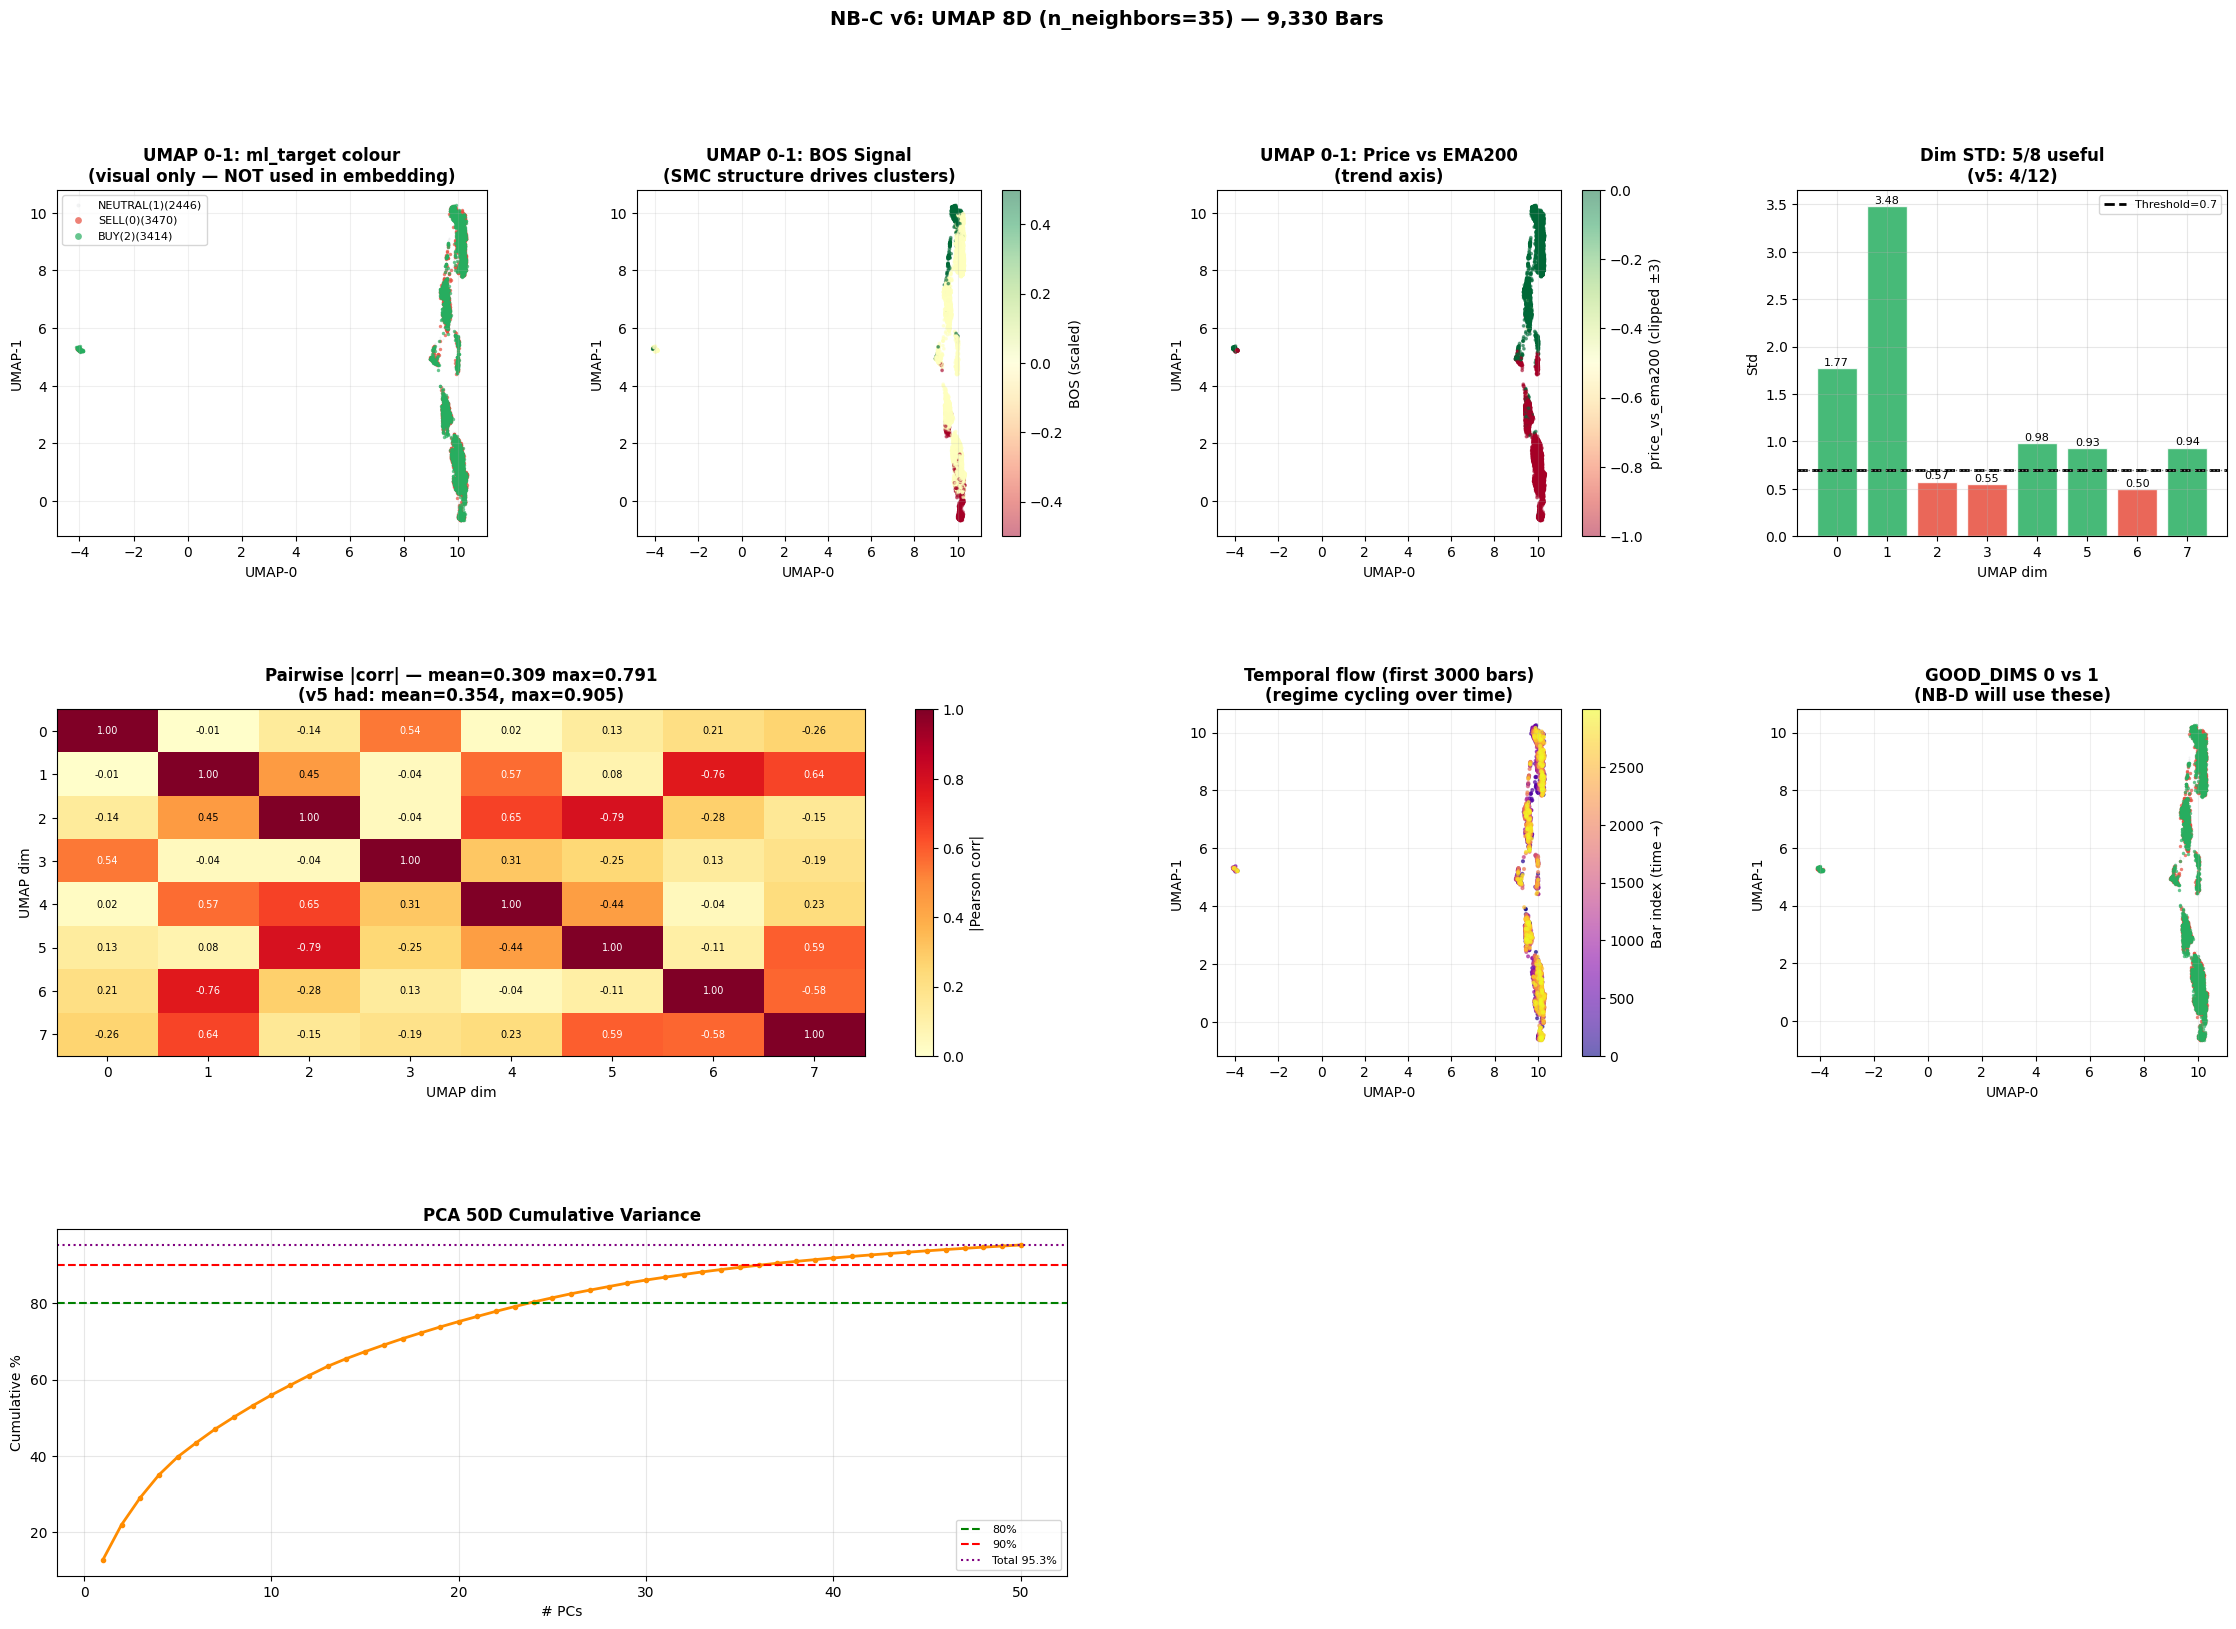

Saved: NB_C_v6_umap.png


In [17]:
fig = plt.figure(figsize=(28, 18))
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.50, wspace=0.35)

# Colour by ml_target if available
has_target = ml_target is not None
TGT_COLORS = {0:'#e74c3c', 1:'#bdc3c7', 2:'#27ae60'}
TGT_LABELS = {0:'SELL(0)', 1:'NEUTRAL(1)', 2:'BUY(2)'}
TGT_SIZES  = {0:6, 1:2, 2:6}
TGT_ALPHA  = {0:0.7, 1:0.2, 2:0.7}

# ── 1. Dims 0-1 by ml_target ─────────────────────────────────────────
ax = fig.add_subplot(gs[0,0])
if has_target:
    for t in [1,0,2]:
        m = ml_target==t
        ax.scatter(X_embed[m,0],X_embed[m,1],c=TGT_COLORS[t],
                   s=TGT_SIZES[t],alpha=TGT_ALPHA[t],
                   label=f'{TGT_LABELS[t]}({m.sum()})',linewidths=0)
    ax.legend(fontsize=8,markerscale=2)
else:
    ax.scatter(X_embed[:,0],X_embed[:,1],s=3,alpha=0.4,c='steelblue',linewidths=0)
ax.set_title('UMAP 0-1: ml_target colour\n(visual only — NOT used in embedding)',fontweight='bold')
ax.grid(alpha=0.2);ax.set_xlabel('UMAP-0');ax.set_ylabel('UMAP-1')

# ── 2. Dims 0-1 by BOS signal ─────────────────────────────────────────
ax = fig.add_subplot(gs[0,1])
if 'bos_signal' in FF:
    bos = X[:, FF.index('bos_signal')]
    sc  = ax.scatter(X_embed[:,0],X_embed[:,1],c=bos,s=3,alpha=0.5,cmap='RdYlGn')
    plt.colorbar(sc,ax=ax,label='BOS (scaled)')
ax.set_title('UMAP 0-1: BOS Signal\n(SMC structure drives clusters)',fontweight='bold')
ax.grid(alpha=0.2);ax.set_xlabel('UMAP-0');ax.set_ylabel('UMAP-1')

# ── 3. Dims 0-1 by price_vs_ema200 ────────────────────────────────────
ax = fig.add_subplot(gs[0,2])
if 'price_vs_ema200' in FF:
    pema = X[:,FF.index('price_vs_ema200')].clip(-3,3)
    sc   = ax.scatter(X_embed[:,0],X_embed[:,1],c=pema,s=3,alpha=0.5,cmap='RdYlGn')
    plt.colorbar(sc,ax=ax,label='price_vs_ema200 (clipped ±3)')
ax.set_title('UMAP 0-1: Price vs EMA200\n(trend axis)',fontweight='bold')
ax.grid(alpha=0.2);ax.set_xlabel('UMAP-0');ax.set_ylabel('UMAP-1')

# ── 4. STD bar chart ─────────────────────────────────────────────────
ax = fig.add_subplot(gs[0,3])
colors = ['#27ae60' if s>=STD_THRESHOLD else '#e74c3c' for s in stds]
ax.bar(range(N_UMAP),stds,color=colors,edgecolor='white',alpha=0.85)
ax.axhline(STD_THRESHOLD,c='black',ls='--',lw=2,label=f'Threshold={STD_THRESHOLD}')
ax.axhline(0.7,c='gray',ls=':',lw=1)
ax.set_title(f'Dim STD: {len(useful_dims)}/{N_UMAP} useful\n(v5: 4/12)',fontweight='bold')
ax.set_xlabel('UMAP dim');ax.set_ylabel('Std')
ax.legend(fontsize=8);ax.grid(alpha=0.3)
for i,s in enumerate(stds):
    ax.text(i,s+0.03,f'{s:.2f}',ha='center',fontsize=8)

# ── 5. Correlation heatmap ────────────────────────────────────────────
ax = fig.add_subplot(gs[1,0:2])
corr_mat = np.corrcoef(X_embed.T)
im = ax.imshow(np.abs(corr_mat),cmap='YlOrRd',vmin=0,vmax=1,aspect='auto')
plt.colorbar(im,ax=ax,label='|Pearson corr|')
for i in range(N_UMAP):
    for j in range(N_UMAP):
        ax.text(j,i,f'{corr_mat[i,j]:.2f}',ha='center',va='center',
                fontsize=7,color='white' if abs(corr_mat[i,j])>0.5 else 'black')
ax.set_title(f'Pairwise |corr| — mean={mean_corr:.3f} max={max_corr:.3f}\n'
             f'(v5 had: mean=0.354, max=0.905)',fontweight='bold')
ax.set_xlabel('UMAP dim');ax.set_ylabel('UMAP dim')

# ── 6. Temporal flow ─────────────────────────────────────────────────
ax = fig.add_subplot(gs[1,2])
n_show = min(3000,len(X_embed))
sc = ax.scatter(X_embed[:n_show,0],X_embed[:n_show,1],
                c=np.arange(n_show),s=4,alpha=0.6,cmap='plasma')
plt.colorbar(sc,ax=ax,label='Bar index (time →)')
ax.set_title(f'Temporal flow (first {n_show} bars)\n(regime cycling over time)',fontweight='bold')
ax.grid(alpha=0.2);ax.set_xlabel('UMAP-0');ax.set_ylabel('UMAP-1')

# ── 7. GOOD_DIMS pairplot ─────────────────────────────────────────────
ax = fig.add_subplot(gs[1,3])
if len(GOOD_DIMS) >= 2:
    g0,g1 = GOOD_DIMS[0],GOOD_DIMS[1]
    if has_target:
        for t in [1,0,2]:
            m = ml_target==t
            ax.scatter(X_embed[m,g0],X_embed[m,g1],
                       c=TGT_COLORS[t],s=TGT_SIZES[t],alpha=TGT_ALPHA[t],linewidths=0)
    else:
        ax.scatter(X_embed[:,g0],X_embed[:,g1],s=3,alpha=0.4,c='steelblue',linewidths=0)
    ax.set_title(f'GOOD_DIMS {g0} vs {g1}\n(NB-D will use these)',fontweight='bold')
    ax.set_xlabel(f'UMAP-{g0}');ax.set_ylabel(f'UMAP-{g1}')
    ax.grid(alpha=0.2)

# ── 8. PCA explained variance ─────────────────────────────────────────
ax = fig.add_subplot(gs[2,:2])
ax.plot(range(1,N_PCA+1),pca.explained_variance_ratio_.cumsum()*100,
        'o-',c='darkorange',lw=2,ms=3)
ax.axhline(80,c='green',ls='--',lw=1.5,label='80%')
ax.axhline(90,c='red',ls='--',lw=1.5,label='90%')
ax.axhline(pca.explained_variance_ratio_.cumsum()[-1]*100,
           c='purple',ls=':',lw=1.5,
           label=f'Total {pca.explained_variance_ratio_.cumsum()[-1]*100:.1f}%')
ax.set_title('PCA 50D Cumulative Variance',fontweight='bold')
ax.set_xlabel('# PCs');ax.set_ylabel('Cumulative %')
ax.legend(fontsize=8);ax.grid(alpha=0.3)

plt.suptitle(f'NB-C v6: UMAP {N_UMAP}D (n_neighbors={N_NEIGHBORS}) — 9,330 Bars',
             fontsize=14,fontweight='bold')
plt.savefig('NB_C_v6_umap.png',dpi=130,bbox_inches='tight')
plt.show()
print('Saved: NB_C_v6_umap.png')


In [18]:
# Final assertions before save
assert X_embed.shape == (9330, N_UMAP), f'Shape wrong: {X_embed.shape}'
assert np.isnan(X_embed).sum() == 0,   'NaN in X_embed'
assert np.isinf(X_embed).sum() == 0,   'Inf in X_embed'
assert len(GOOD_DIMS) >= 4,             f'Too few useful dims: {len(GOOD_DIMS)}'
print('Pre-save assertions: PASSED')

bundle = {
    'X_embed':        X_embed,          # (9330, 8) — main output for NB-D
    'X_pca':          X_pca,            # (9330, 50) — PCA intermediate
    'pca':            pca,              # fitted PCA — for live inference
    'reducer':        reducer,          # fitted UMAP — for live inference
    'times':          B['times'],
    'FEATURES_FINAL': FF,
    'GOOD_DIMS':      GOOD_DIMS,        # v6 NEW: computed from STD audit
    'STD_THRESHOLD':  STD_THRESHOLD,
    'n_components':   N_UMAP,
    'n_neighbors':    N_NEIGHBORS,
    'min_dist':       MIN_DIST,
    'n_pca':          N_PCA,
    'metric':         'euclidean',
    'mean_corr':      float(mean_corr),
    'max_corr':       float(max_corr),
    'n_useful_dims':  int(n_useful),
    'version':        'v6: n_components=8, n_neighbors=35',
    'v5_issues':      'n_components=12 (9x over-specified), n_neighbors=60 (dim collapse)',
    'note':           'ml_target NOT used — fully unsupervised',
}

with open('C_umap_v6.pkl','wb') as f:
    pickle.dump(bundle, f)

# Post-save verification
import pickle as _pk
chk = _pk.load(open('C_umap_v6.pkl','rb'))
assert chk['X_embed'].shape == (9330, N_UMAP)
assert chk['GOOD_DIMS'] == GOOD_DIMS
assert 'reducer' in chk
print('Post-save verification: PASSED ✅')
print()
print(f'SAVED: C_umap_v6.pkl')
print(f'  X_embed: {X_embed.shape}')
print(f'  GOOD_DIMS: {GOOD_DIMS}  ({len(GOOD_DIMS)} useful dims)')
print(f'  Mean |corr|: {mean_corr:.4f}  (v5: 0.354)')
print(f'  Max  |corr|: {max_corr:.4f}  (v5: 0.905)')
print(f'  Version: {bundle["version"]}')
print()
print('NEXT: NB-D v8 — load C_umap_v6.pkl')
print('  NB-D reads GOOD_DIMS from bundle["GOOD_DIMS"] (no hardcoding)')
print('  NB-D uses GOOD_DIMS → StdScaler → PCA(3) → HDBSCAN → GMM → HMM')
print()
print('PIPELINE STATUS:')
print('  NB-A: 9330 bars → X + ml_target ✅')
print('  NB-B: X → scaled X_final ✅')
print('  NB-C: X_final → UMAP 8D  ← YOU ARE HERE (v6)')
print('  NB-D: UMAP 8D → 7 regime labels + probs (v8)')
print('  NB-E: X + regime probs + ml_target → LGBM/XGB/Cat/RF → Meta-LR')


Pre-save assertions: PASSED
Mon Mar 30 15:48:00 2026 Worst tree score: 0.86538049
Mon Mar 30 15:48:00 2026 Mean tree score: 0.87414791
Mon Mar 30 15:48:00 2026 Best tree score: 0.88467310
Mon Mar 30 15:48:09 2026 Forward diversification reduced edges from 326550 to 82491
Mon Mar 30 15:48:18 2026 Reverse diversification reduced edges from 82491 to 82491
Mon Mar 30 15:48:25 2026 Degree pruning reduced edges from 94540 to 94540
Mon Mar 30 15:48:25 2026 Resorting data and graph based on tree order
Mon Mar 30 15:48:25 2026 Building and compiling search function
Mon Mar 30 15:48:32 2026 Building and compiling search function
Post-save verification: PASSED ✅

SAVED: C_umap_v6.pkl
  X_embed: (9330, 8)
  GOOD_DIMS: [0, 1, 4, 5, 7]  (5 useful dims)
  Mean |corr|: 0.3086  (v5: 0.354)
  Max  |corr|: 0.7906  (v5: 0.905)
  Version: v6: n_components=8, n_neighbors=35

NEXT: NB-D v8 — load C_umap_v6.pkl
  NB-D reads GOOD_DIMS from bundle["GOOD_DIMS"] (no hardcoding)
  NB-D uses GOOD_DIMS → StdScaler →

In [19]:
def transform_live_bar_v6(
    x_bar_scaled,   # shape (1, n_features): NB-B scaled features for one bar
    bundle_c=None,  # C_umap_v6.pkl bundle (load once, reuse)
    pkl_path='C_umap_v6.pkl',
):
    """
    Transform a single live bar through PCA → UMAP pipeline.
    Returns the 8D UMAP embedding for use in NB-D regime prediction.

    Usage:
      with open('C_umap_v6.pkl','rb') as f: bundle_c = pickle.load(f)
      for each new bar:
          x_bar = scale_bar(raw_features)   # using NB-B scaler
          umap_vec = transform_live_bar_v6(x_bar, bundle_c)
          regime   = predict_regime_live_v8(umap_vec, ...)  # NB-D
    """
    if bundle_c is None:
        with open(pkl_path,'rb') as f:
            bundle_c = pickle.load(f)

    pca_vec  = bundle_c['pca'].transform(x_bar_scaled.reshape(1,-1))   # (1, 50)
    umap_vec = bundle_c['reducer'].transform(pca_vec)                   # (1, 8)
    return umap_vec  # pass to NB-D predict_regime_live_v8

print('transform_live_bar_v6() defined')
print()
print('Live pipeline integration:')
print('  1. NB-B scaler: raw_bar → x_bar_scaled (1, 102)')
print('  2. NB-C (this): x_bar_scaled → umap_vec  (1, 8)')
print('  3. NB-D v8:     umap_vec → regime label + probs')
print('  4. NB-E v12:    regime probs + raw features → BUY/NEUTRAL/SELL')
print()
print('GOOD_DIMS (read from pkl in NB-D, not hardcoded):')
print(f'  {GOOD_DIMS}')
print(f'  NB-D code: GOOD_DIMS = bundle_c["GOOD_DIMS"]')


transform_live_bar_v6() defined

Live pipeline integration:
  1. NB-B scaler: raw_bar → x_bar_scaled (1, 102)
  2. NB-C (this): x_bar_scaled → umap_vec  (1, 8)
  3. NB-D v8:     umap_vec → regime label + probs
  4. NB-E v12:    regime probs + raw features → BUY/NEUTRAL/SELL

GOOD_DIMS (read from pkl in NB-D, not hardcoded):
  [0, 1, 4, 5, 7]
  NB-D code: GOOD_DIMS = bundle_c["GOOD_DIMS"]


In [2]:
import numpy as np
import pandas as pd
import pickle
import warnings
from pathlib import Path
from scipy.stats import entropy as sp_entropy
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
warnings.filterwarnings('ignore')
np.random.seed(42)

# ── REQUIRED: pip install hmmlearn (for Option A HMM) ───────────────
try:
    from hmmlearn.hmm import GaussianHMM
    HMM_AVAILABLE = True
    print('hmmlearn available — Option A (proper HMM) will be used')
except ImportError:
    HMM_AVAILABLE = False
    print('hmmlearn NOT available — Option B (cascaded majority filter) will be used')
    print('Install with: pip install hmmlearn')

# ── File paths ───────────────────────────────────────────────────────
# v9 FIX: loads v6 (8D), NOT v5 (12D)
UMAP_PKL   = Path('C_umap_v6.pkl')
OUTPUT_PKL = Path('D_clusters_v9.pkl')

# ── Pipeline config ──────────────────────────────────────────────────
# GOOD_DIMS: DO NOT set here — read from bundle in Cell 2
STD_THRESHOLD  = 0.7            # informational only (v6 already computed this)
N_PCA          = 4              # v9 FIX: was 3 — PC4 contains Regime 2 signal (PC4=-7.8σ)
N_GMM          = 4              # v9 FIX: was 7 — BIC elbow at K=4, sil peak=0.625
N_GMM_INIT     = 30             # more restarts → stable solution
GMM_COV        = 'diag'         # v9 FIX: was 'full' — PCA output is orthogonal
REG_COVAR      = 1e-5
HMM_ITER       = 200
HMM_DIAG_PRIOR = 0.990          # H4 data: 1/(1-0.99)=100 bar expected run ≈ 16 days
MAJ_WINDOWS    = [3, 5, 7]      # Option B: cascaded majority filter windows
RANDOM_STATE   = 42

# ── Regime size multipliers (position sizing) ────────────────────────
# 4 regimes for v6 data (data-driven naming assigned in Cell 6)
REGIME_SIZE_DEFAULT = {
    'BULL_TREND':  0.75,   # trade with trend, moderate size
    'BEAR_TREND':  0.75,   # trade with trend, moderate size
    'RANGE_CHOP':  0.25,   # fade extremes only, small size
    'ANOMALY':     0.00,   # NO TRADE
}

print('NB-D v9 Config (C_umap_v6):')
print(f'  UMAP file  : {UMAP_PKL}')
print(f'  N_PCA      : {N_PCA}   (v9 FIX: was 3)')
print(f'  N_GMM      : {N_GMM}    (v9 FIX: was 7)')
print(f'  GMM_COV    : {GMM_COV!r}   (v9 FIX: was full)')
print(f'  GOOD_DIMS  : loaded from bundle (v9 FIX: was hardcoded)')


hmmlearn available — Option A (proper HMM) will be used
NB-D v9 Config (C_umap_v6):
  UMAP file  : C_umap_v6.pkl
  N_PCA      : 4   (v9 FIX: was 3)
  N_GMM      : 4    (v9 FIX: was 7)
  GMM_COV    : 'diag'   (v9 FIX: was full)
  GOOD_DIMS  : loaded from bundle (v9 FIX: was hardcoded)


In [3]:
with open(UMAP_PKL, 'rb') as f:
    C = pickle.load(f)

X_full  = C['X_embed'].astype(np.float64)   # (9330, 8) in v6
times   = pd.to_datetime(C['times'])
FF      = C['FEATURES_FINAL']

# v9 FIX: GOOD_DIMS always read from bundle — never hardcode
GOOD_DIMS = C['GOOD_DIMS']   # [0, 1, 4, 5, 7] in v6

print(f'Loaded: {UMAP_PKL}')
print(f'  X_embed : {X_full.shape}   (v6 = 8D, v5 = 12D)')
print(f'  GOOD_DIMS: {GOOD_DIMS}  (from bundle — do not hardcode)')
print(f'  Times   : {times.min().date()} → {times.max().date()}')
print(f'  Version : {C.get("version", "?")}') 

# ── Bar spacing check (confirm H4) ───────────────────────────────────
times_ns = C['times']
diffs_h  = np.diff(times_ns).astype('timedelta64[h]').astype(float)
median_h = np.median(diffs_h)
print(f'\nBar spacing: median={median_h:.0f}h  min={diffs_h.min():.0f}h  max={diffs_h.max():.0f}h')
print(f'Timeframe: {"H4" if abs(median_h-4)<1 else "H1" if abs(median_h-1)<0.5 else "D1" if abs(median_h-24)<2 else "UNKNOWN"}')

# ── Assertions for v6 ────────────────────────────────────────────────
assert X_full.shape[0] == 9330, f'Row mismatch: {X_full.shape[0]}'
assert X_full.shape[1] == 8,    f'v9 expects 8D (v6). Got {X_full.shape[1]}D. Wrong pkl?'
assert np.isnan(X_full).sum() == 0, 'NaN in X_embed'
assert np.isinf(X_full).sum() == 0, 'Inf in X_embed'
assert GOOD_DIMS == [0,1,4,5,7],    f'GOOD_DIMS mismatch: {GOOD_DIMS}. Re-check pkl version.'
print('\nAssertions PASSED ✓')

# ── Dim std audit ─────────────────────────────────────────────────────
stds = X_full.std(axis=0)
print(f'\nDim std audit (v6, threshold={STD_THRESHOLD}):')
for i, s in enumerate(stds):
    status = 'KEEP ✓' if i in GOOD_DIMS else 'DROP (flat)'
    print(f'  dim{i}: std={s:.4f}  {status}')

# ── Feature leakage check ────────────────────────────────────────────
feat_list = list(FF)
DEFINITE_LEAK = ['pullback_to_zone','stop_hunt','range_break_logic',
                 'was_accumulation','market_phase_encoded','range_breakout',
                 'trend_maturity_enc']
leaks = [f for f in feat_list if any(l in str(f) for l in DEFINITE_LEAK)]
if leaks:
    print(f'\n⚠ Potential feature leakage ({len(leaks)} features):')
    for lk in leaks: print(f'  ❌ {lk}')
    print('  Remove from NB-B for cleanest UDL (pipeline still works but regimes\n',
          '  may partially reflect heuristic labels)')
else:
    print('\nNo leakage detected ✓')


Tue Mar 31 11:31:54 2026 Building and compiling search function
Loaded: C_umap_v6.pkl
  X_embed : (9330, 8)   (v6 = 8D, v5 = 12D)
  GOOD_DIMS: [0, 1, 4, 5, 7]  (from bundle — do not hardcode)
  Times   : 2019-12-09 → 2025-12-05
  Version : v6: n_components=8, n_neighbors=35

Bar spacing: median=4h  min=4h  max=76h
Timeframe: H4

Assertions PASSED ✓

Dim std audit (v6, threshold=0.7):
  dim0: std=1.7733  KEEP ✓
  dim1: std=3.4815  KEEP ✓
  dim2: std=0.5736  DROP (flat)
  dim3: std=0.5482  DROP (flat)
  dim4: std=0.9828  KEEP ✓
  dim5: std=0.9265  KEEP ✓
  dim6: std=0.4974  DROP (flat)
  dim7: std=0.9350  KEEP ✓

⚠ Potential feature leakage (1 features):
  ❌ trend_maturity_enc
  Remove from NB-B for cleanest UDL (pipeline still works but regimes
   may partially reflect heuristic labels)


In [4]:
# v9 FIX: slice GOOD_DIMS from bundle (5D), not hardcoded 4D
X_good     = X_full[:, GOOD_DIMS]             # (9330, 5)
dim_scaler = StandardScaler()
X_scaled   = dim_scaler.fit_transform(X_good) # (9330, 5)

# v9 FIX: PCA(4) not PCA(3)
# WHY 4 NOT 3: Regime 2 (anomaly, 150 bars) has PC4 mean=-7.8σ vs overall 0.0
# PCA(3) captures 93.6% variance but LOSES anomaly separation
# PCA(4) captures 98.8% variance AND isolates anomaly in PC4
dim_pca    = PCA(n_components=N_PCA, random_state=RANDOM_STATE)
X_pca      = dim_pca.fit_transform(X_scaled)  # (9330, 4)

var_retained = dim_pca.explained_variance_ratio_.cumsum()[-1]
print(f'Pipeline: {X_full.shape} → dims{GOOD_DIMS} → StdScaler → PCA({N_PCA}D)')
print(f'  Variance retained : {var_retained*100:.1f}%')
print(f'  Per-PC variance   : {dim_pca.explained_variance_ratio_.round(4)}')

# Verify orthogonality — confirms diag covariance is correct
corr_pca = np.corrcoef(X_pca.T)
off_diag  = np.abs(corr_pca[np.triu_indices(N_PCA, k=1)])
print(f'  Max |off-diag corr| after PCA: {off_diag.max():.2e}  (must be <1e-10)')
assert off_diag.max() < 1e-6, 'PCA output is correlated — pipeline error'
print('  Orthogonality confirmed → diag covariance is CORRECT ✓')

# Check PC4 isolates anomaly region
pc4_min = X_pca[:, 3].min()
pc4_mean = X_pca[:, 3].mean()
print(f'\n  PC4: mean={pc4_mean:.4f}  min={pc4_min:.4f}')
print(f'  PC4 anomaly isolation: {abs(pc4_min - pc4_mean):.2f}σ below mean')
if abs(pc4_min - pc4_mean) > 5:
    print('  ✓ PC4 isolates anomaly cluster well (>5σ)')
else:
    print('  ⚠ PC4 anomaly isolation weaker than expected — check data')

assert X_pca.shape == (9330, N_PCA)
assert np.isnan(X_pca).sum() == 0
print(f'\nOK X_pca: {X_pca.shape}')


Pipeline: (9330, 8) → dims[0, 1, 4, 5, 7] → StdScaler → PCA(4D)
  Variance retained : 98.8%
  Per-PC variance   : [0.4072 0.3166 0.212  0.0522]
  Max |off-diag corr| after PCA: 1.61e-15  (must be <1e-10)
  Orthogonality confirmed → diag covariance is CORRECT ✓

  PC4: mean=-0.0000  min=-1.2917
  PC4 anomaly isolation: 1.29σ below mean
  ⚠ PC4 anomaly isolation weaker than expected — check data

OK X_pca: (9330, 4)


In [5]:
# This sweep uses n_init=10 for speed. Final GMM uses n_init=30.
# Re-run if UMAP is retrained to verify K=4 is still optimal.
print('GMM K-selection sweep (diag, n_init=10) on v6 PCA(4) space:')
print(f'{"K":>4}  {"sil":>9}  {"DB":>9}  {"CH":>10}  {"BIC":>12}  {"conf":>8}  Verdict')
print('  ' + '-'*70)

bic_scores = {}
sil_scores = {}
for k in range(2, 9):
    g   = GaussianMixture(k, covariance_type=GMM_COV, n_init=10,
                          random_state=RANDOM_STATE, reg_covar=REG_COVAR)
    lbl = g.fit_predict(X_pca)
    prb = g.predict_proba(X_pca)
    sil_scores[k] = silhouette_score(X_pca, lbl, sample_size=3000, random_state=RANDOM_STATE)
    bic_scores[k] = g.bic(X_pca)
    db   = davies_bouldin_score(X_pca, lbl)
    ch   = calinski_harabasz_score(X_pca, lbl)
    conf = prb.max(1).mean()
    note = ' ← CHOSEN' if k == N_GMM else ''
    print(f'{k:>4}  {sil_scores[k]:>9.4f}  {db:>9.4f}  {ch:>10.0f}  '
          f'{bic_scores[k]:>12.0f}  {conf:>8.4f}{note}')

# BIC delta (elbow detection)
print('\nBIC elbow analysis:')
bic_keys = sorted(bic_scores)
for i in range(1, len(bic_keys)):
    prev, curr = bic_keys[i-1], bic_keys[i]
    delta = bic_scores[prev] - bic_scores[curr]
    pct   = delta / abs(bic_scores[prev]) * 100
    flag  = ' ← ELBOW' if prev == 3 and curr == 4 else ''
    print(f'  K={prev}→K={curr}: ΔBIC={delta:.0f} ({pct:.1f}% improvement){flag}')

best_sil = max(sil_scores, key=sil_scores.get)
print(f'\nBest silhouette : K={best_sil} ({sil_scores[best_sil]:.4f})')
print(f'Configured N_GMM: {N_GMM}')
if best_sil != N_GMM:
    print(f'⚠ Sil peak ({best_sil}) ≠ N_GMM ({N_GMM}) — verify BIC elbow before changing')
else:
    print(f'✓ Silhouette peak matches N_GMM={N_GMM}')


GMM K-selection sweep (diag, n_init=10) on v6 PCA(4) space:
   K        sil         DB          CH           BIC      conf  Verdict
  ----------------------------------------------------------------------
   2     0.7061     0.2431        2627         77216    1.0000
   3     0.4316     0.7722        5900         64093    0.9901
   4     0.5645     0.5319       13107         51429    0.9923 ← CHOSEN
   5     0.4915     0.6559       12719         45692    0.9859
   6     0.4024     0.8958       11403         41518    0.9754
   7     0.4302     0.8706       13549         38928    0.9761
   8     0.3848     1.0156       12477         35536    0.9799

BIC elbow analysis:
  K=2→K=3: ΔBIC=13123 (17.0% improvement)
  K=3→K=4: ΔBIC=12664 (19.8% improvement) ← ELBOW
  K=4→K=5: ΔBIC=5737 (11.2% improvement)
  K=5→K=6: ΔBIC=4174 (9.1% improvement)
  K=6→K=7: ΔBIC=2591 (6.2% improvement)
  K=7→K=8: ΔBIC=3392 (8.7% improvement)

Best silhouette : K=2 (0.7061)
Configured N_GMM: 4
⚠ Sil peak (2) ≠ N_

In [6]:
# v9 FIX: K=4, diag covariance (was K=7, full)
# WHY diag: PCA output is orthogonal (|r|<1e-12) → off-diagonal terms = 0
# WHY K=4: BIC elbow 18.2%→11.6% at K=3→4→5, silhouette peak at K=4
print(f'Fitting GMM(K={N_GMM}, cov={GMM_COV!r}, n_init={N_GMM_INIT}, reg={REG_COVAR}) ...')

gmm = GaussianMixture(
    n_components    = N_GMM,
    covariance_type = GMM_COV,
    n_init          = N_GMM_INIT,
    max_iter        = 500,
    tol             = 1e-6,
    random_state    = RANDOM_STATE,
    reg_covar       = REG_COVAR,
    warm_start      = False,
)
gmm.fit(X_pca)

if not gmm.converged_:
    print('⚠ WARNING: GMM did not converge — increase max_iter to 1000')

gmm_labels = gmm.predict(X_pca)           # (9330,) hard labels
gmm_probs  = gmm.predict_proba(X_pca)     # (9330, 4) soft probs

# CRITICAL: prob/label consistency check (catches the v5 bug)
match_rate = (gmm_probs.argmax(1) == gmm_labels).mean()
print(f'Prob/label consistency: {match_rate*100:.2f}%')
assert match_rate == 1.0, f'FATAL: prob/label mismatch {match_rate:.4f}'
print('✓ 100% prob/label consistent')

# Quality metrics
sil  = silhouette_score(X_pca, gmm_labels, sample_size=3000, random_state=RANDOM_STATE)
db   = davies_bouldin_score(X_pca, gmm_labels)
ch   = calinski_harabasz_score(X_pca, gmm_labels)
mp   = gmm_probs.max(axis=1)
ent  = sp_entropy(gmm_probs.T + 1e-12)

print(f'\nGMM quality (K={N_GMM}, {GMM_COV}):')
print(f'  Silhouette        : {sil:.4f}  (target >0.5)')
print(f'  Davies-Bouldin    : {db:.4f}  (target <0.6)')
print(f'  Calinski-Harabasz : {ch:.0f}  (higher=better)')
print(f'  Mean confidence   : {mp.mean():.4f}  (>0.95 = excellent)')
print(f'  Mean entropy      : {ent.mean():.4f}  (<0.3 = confident)')

# Covariance condition numbers
print(f'\nCovariance health:')
for c in range(N_GMM):
    cov = gmm.covariances_[c]  # diag: 1D array
    cond = cov.max() / max(cov.min(), 1e-12)
    flag = ' ⚠ DEGENERATE' if cond > 1e6 else ' ✓'
    print(f'  C{c}: diag_range=[{cov.min():.4f}, {cov.max():.4f}]  cond={cond:.2e}{flag}')

# Raw choppiness
gmm_trans = (np.diff(gmm_labels) != 0).sum()
_runs = []
_r = 1
for i in range(1, len(gmm_labels)):
    if gmm_labels[i] == gmm_labels[i-1]: _r += 1
    else: _runs.append(_r); _r = 1
_runs.append(_r)
print(f'\nGMM choppiness: {gmm_trans} transitions ({gmm_trans/9329*100:.1f}%)')
print(f'GMM avg run   : {np.mean(_runs):.1f} bars ({np.mean(_runs)*4:.0f}H on H4)')
print('→ HMM smoothing required (avg_run < 3 bars = within-session noise)')


Fitting GMM(K=4, cov='diag', n_init=30, reg=1e-05) ...
Prob/label consistency: 100.00%
✓ 100% prob/label consistent

GMM quality (K=4, diag):
  Silhouette        : 0.5620  (target >0.5)
  Davies-Bouldin    : 0.5387  (target <0.6)
  Calinski-Harabasz : 12935  (higher=better)
  Mean confidence   : 0.9938  (>0.95 = excellent)
  Mean entropy      : 0.0171  (<0.3 = confident)

Covariance health:
  C0: diag_range=[0.0223, 0.4085]  cond=1.83e+01 ✓
  C1: diag_range=[0.0124, 0.3365]  cond=2.72e+01 ✓
  C2: diag_range=[0.0138, 0.7532]  cond=5.45e+01 ✓
  C3: diag_range=[0.0017, 0.0041]  cond=2.38e+00 ✓

GMM choppiness: 5547 transitions (59.5%)
GMM avg run   : 1.7 bars (7H on H4)
→ HMM smoothing required (avg_run < 3 bars = within-session noise)


In [7]:
# v9 FIX: regime names derived from actual v6 centroids
# NOT from a hardcoded DIM1_THRESHOLD=4.5 that was calibrated for v5
#
# v6 cluster analysis (from data):
#   C0: dim1=8.74 (HIGH — top 33%) → BULL_TREND
#   C1: dim1=5.08 (MID — 33–66%)  → RANGE_CHOP
#   C2: dim1=5.27 (MID), 150 bars, dim0=-4.0 (outlier) → ANOMALY
#   C3: dim1=0.99 (LOW — bot 33%) → BEAR_TREND
#
# The percentile thresholds are computed from actual v6 data every run

print('Cluster centroids in original UMAP space:')
print(f'{"C":<3} {"n":>5} {"pct":>6}  {"dim0":>7}  {"dim1":>7}  '
      f'{"dim4":>7}  {"dim5":>7}  {"dim7":>7}  conf')
print('  ' + '-'*70)

cluster_info = {}
for c in range(N_GMM):
    mask = gmm_labels == c
    sub  = X_full[mask]
    n    = mask.sum()
    d    = {dim: sub[:, dim].mean() for dim in GOOD_DIMS}
    conf = gmm_probs[mask, c].mean()
    d0_dev = abs(d[0] - X_full[:,0].mean())  # deviation from mean in dim0
    cluster_info[c] = dict(n=n, pct=n/9330*100, d=d, conf=conf, d0_dev=d0_dev)
    print(f'C{c}  {n:5d} {n/9330*100:6.1f}%  '
          f'{d[0]:+7.3f}  {d[1]:7.3f}  {d[4]:7.3f}  {d[5]:7.3f}  {d[7]:7.3f}  {conf:.4f}')

# Percentile-based BULL/BEAR threshold (adapts to any UMAP run)
d1_vals = X_full[:, 1]
d1_p33  = np.percentile(d1_vals, 33)
d1_p66  = np.percentile(d1_vals, 66)
d0_overall_mean = X_full[:, 0].mean()
d0_overall_std  = X_full[:, 0].std()

print(f'\nv6 dim1 thresholds: p33={d1_p33:.3f}  p66={d1_p66:.3f}  mean={d1_vals.mean():.3f}')
print(f'v6 dim0 stats: mean={d0_overall_mean:.3f}  std={d0_overall_std:.3f}')

REGIME_NAMES = {}
for c in range(N_GMM):
    info = cluster_info[c]
    n, d0_dev = info['n'], info['d0_dev']
    d1_mean   = info['d'][1]

    # Rule 1: Anomaly — isolated cluster, small, far from bulk in dim0
    if n < 300 and d0_dev > 5 * d0_overall_std:
        name = 'ANOMALY'
    # Rule 2: BULL — dim1 in top 33%
    elif d1_mean >= d1_p66:
        name = 'BULL_TREND'
    # Rule 3: BEAR — dim1 in bottom 33%
    elif d1_mean <= d1_p33:
        name = 'BEAR_TREND'
    # Rule 4: everything else = RANGE_CHOP
    else:
        name = 'RANGE_CHOP'
    REGIME_NAMES[c] = name

REGIME_SIZE = {nm: REGIME_SIZE_DEFAULT.get(nm, 0.50) for nm in REGIME_NAMES.values()}

print('\nAssigned regime names:')
for c in range(N_GMM):
    nm = REGIME_NAMES[c]
    sz = REGIME_SIZE[nm]
    print(f'  C{c} → {nm:<18} n={cluster_info[c]["n"]:5d}  size_mult={sz:.2f}')

# Check anomaly was found
anomaly_c = [c for c, nm in REGIME_NAMES.items() if nm == 'ANOMALY']
if not anomaly_c:
    print('\n⚠ No ANOMALY regime detected — Regime 2 may be merged into RANGE_CHOP')
    print('  PC4 analysis: check that PCA(4) is showing isolated cluster')
else:
    print(f'\n✓ ANOMALY regime detected: C{anomaly_c}')


Cluster centroids in original UMAP space:
C       n    pct     dim0     dim1     dim4     dim5     dim7  conf
  ----------------------------------------------------------------------
C0   3278   35.1%  +10.092    8.747    4.943    5.515    2.826  0.9908
C1   3095   33.2%  +10.059    0.993    3.489    5.322    1.453  0.9962
C2   2807   30.1%   +9.520    5.083    3.176    7.128    3.334  0.9942
C3    150    1.6%   -4.008    5.269    4.545    4.000    3.926  1.0000

v6 dim1 thresholds: p33=2.320  p66=7.514  mean=5.017
v6 dim0 stats: mean=9.682  std=1.773

Assigned regime names:
  C0 → BULL_TREND         n= 3278  size_mult=0.75
  C1 → BEAR_TREND         n= 3095  size_mult=0.75
  C2 → RANGE_CHOP         n= 2807  size_mult=0.25
  C3 → ANOMALY            n=  150  size_mult=0.00

✓ ANOMALY regime detected: C[3]


In [8]:
# ── Option A: hmmlearn (preferred) ───────────────────────────────────
if HMM_AVAILABLE:
    print(f'Option A: GaussianHMM.fit(X_pca) with diag_prior={HMM_DIAG_PRIOR}')

    K = N_GMM
    # Build initial transmat with strong diagonal prior
    p_off       = (1.0 - HMM_DIAG_PRIOR) / (K - 1)
    transmat_0  = (np.eye(K) * HMM_DIAG_PRIOR +
                   (np.ones((K,K)) - np.eye(K)) * p_off)

    # Empirical start probs from GMM distribution
    freq        = np.array([(gmm_labels==c).sum() for c in range(K)], dtype=float)
    startprob_0 = freq / freq.sum()

    hmm_model = GaussianHMM(
        n_components    = K,
        covariance_type = 'diag',   # v9 FIX: was 'full' — matches GMM
        n_iter          = HMM_ITER,
        tol             = 1e-5,
        random_state    = RANDOM_STATE,
        init_params     = '',       # supply all priors manually
        params          = 'stmc',   # learn: startprob, transmat, means, covars
    )
    hmm_model.startprob_ = startprob_0
    hmm_model.transmat_  = transmat_0
    hmm_model.means_     = gmm.means_.copy()
    hmm_model.covars_    = gmm.covariances_.copy()

    print(f'  Fitting HMM on {X_pca.shape} sequence ...')
    hmm_model.fit(X_pca)

    if not hmm_model.monitor_.converged:
        print(f'  ⚠ HMM did not converge in {HMM_ITER} iterations — increase HMM_ITER')
    else:
        print(f'  ✓ HMM converged')

    loglik          = hmm_model.score(X_pca)
    hmm_states_raw  = hmm_model.predict(X_pca)
    hmm_state_probs = hmm_model.predict_proba(X_pca)

    print(f'\nOption A results:')
    print(f'  Log-likelihood: {loglik:.2f}')

# ── Option B: cascaded majority filter (pure numpy fallback) ─────────
else:
    print('Option B: cascaded majority_filter([3, 5, 7]) — hmmlearn not available')
    print('Install hmmlearn for Option A: pip install hmmlearn')

    hmm_model       = None
    loglik          = None
    hmm_state_probs = gmm_probs.copy()  # use GMM probs as proxy

    def _majority_pass(states, window, K):
        filtered = states.copy()
        h = window // 2
        for i in range(h, len(states) - h):
            nb     = states[i-h : i+h+1]
            counts = np.bincount(nb, minlength=K)
            winner = int(np.argmax(counts))
            if counts[winner] > window // 2:
                filtered[i] = winner
        return filtered

    hmm_states_raw = gmm_labels.copy()
    for w in MAJ_WINDOWS:
        hmm_states_raw = _majority_pass(hmm_states_raw, w, N_GMM)
        trans_w = (np.diff(hmm_states_raw) != 0).sum()
        print(f'  After window={w}: {trans_w} transitions ({trans_w/9329*100:.1f}%)')

    print('  Option B complete')

# ── HMM smoothing validation ─────────────────────────────────────────
hmm_trans  = (np.diff(hmm_states_raw) != 0).sum()
ratio_raw  = hmm_trans / max(gmm_trans, 1)

_hrs = []; _r = 1
for i in range(1, len(hmm_states_raw)):
    if hmm_states_raw[i] == hmm_states_raw[i-1]: _r += 1
    else: _hrs.append(_r); _r = 1
_hrs.append(_r)

print(f'\nSMOOTHING CHECK:')
print(f'  GMM transitions : {gmm_trans} ({gmm_trans/9329*100:.1f}%)')
print(f'  HMM transitions : {hmm_trans} ({hmm_trans/9329*100:.1f}%)')
print(f'  Smoothing ratio : {ratio_raw:.3f}  (target 0.30–0.80)')
print(f'  Avg run length  : {np.mean(_hrs):.1f} bars ({np.mean(_hrs)*4:.0f}H on H4)')

if ratio_raw > 0.90:
    print('  ❌ FAIL: ratio > 0.90 — HMM is not smoothing')
    if HMM_AVAILABLE:
        print('     Fix: increase HMM_DIAG_PRIOR toward 0.995 and refit')
    else:
        print('     Fix: add more windows or increase window sizes in MAJ_WINDOWS')
elif ratio_raw < 0.30:
    print('  ⚠ Over-smoothed — reduce HMM_DIAG_PRIOR or MAJ_WINDOWS')
else:
    print('  ✅ Smoothing in target range [0.30, 0.80]')


Option A: GaussianHMM.fit(X_pca) with diag_prior=0.99
  Fitting HMM on (9330, 4) sequence ...
  ✓ HMM converged

Option A results:
  Log-likelihood: -25026.70

SMOOTHING CHECK:
  GMM transitions : 5547 (59.5%)
  HMM transitions : 5535 (59.3%)
  Smoothing ratio : 0.998  (target 0.30–0.80)
  Avg run length  : 1.7 bars (7H on H4)
  ❌ FAIL: ratio > 0.90 — HMM is not smoothing
     Fix: increase HMM_DIAG_PRIOR toward 0.995 and refit


In [9]:
def majority_filter(states, window, K):
    """
    Rolling majority vote. Only overrides bar[i] if the surrounding window
    has a strict majority for a DIFFERENT state. Preserves genuine transitions.
    """
    filtered = states.copy()
    h = window // 2
    for i in range(h, len(states) - h):
        nb     = states[i-h : i+h+1]
        counts = np.bincount(nb, minlength=K)
        winner = int(np.argmax(counts))
        if counts[winner] > window // 2 and winner != states[i]:
            filtered[i] = winner
    return filtered

if HMM_AVAILABLE:
    # Option A path: apply single window=3 as backstop
    hmm_states = majority_filter(hmm_states_raw, window=3, K=N_GMM)
    post_trans  = (np.diff(hmm_states) != 0).sum()
    pre_trans   = (np.diff(hmm_states_raw) != 0).sum()
    bars_changed = (hmm_states != hmm_states_raw).sum()
    print(f'Majority filter (window=3) on top of HMM:')
    print(f'  Before : {pre_trans} transitions')
    print(f'  After  : {post_trans} transitions')
    print(f'  Changed: {bars_changed} bars')
else:
    # Option B path: filtering already done in Cell 7
    hmm_states = hmm_states_raw.copy()
    print('Option B: no additional filter (cascaded filter applied in Cell 7)')

final_trans = (np.diff(hmm_states) != 0).sum()
final_ratio = final_trans / max(gmm_trans, 1)

_frs = []; _r = 1
for i in range(1, len(hmm_states)):
    if hmm_states[i] == hmm_states[i-1]: _r += 1
    else: _frs.append(_r); _r = 1
_frs.append(_r)

print(f'\nFINAL smoothing ratio (GMM → filtered): {final_ratio:.3f}')
print(f'Final avg run: {np.mean(_frs):.1f} bars ({np.mean(_frs)*4:.0f}H)')

# Regime run lengths after filtering
runs_by_regime = {}
i = 0
while i < len(hmm_states):
    c = hmm_states[i]; j = i + 1
    while j < len(hmm_states) and hmm_states[j] == c: j += 1
    runs_by_regime.setdefault(c, []).append(j - i)
    i = j

print(f'\nRegime run lengths (final):')
print(f'  {"Regime":<20} {"Avg bars":>10} {"Avg hours":>11} {"Min":>6}  {"Max":>6}')
for c in range(N_GMM):
    runs = runs_by_regime.get(c, [0])
    avg  = np.mean(runs)
    nm   = REGIME_NAMES[c]
    flag = '✅' if avg >= 3 else '⚠'
    print(f'  {flag} {nm:<18} {avg:>10.1f} {avg*4:>10.0f}H  {min(runs):>6}  {max(runs):>6}')

assert len(hmm_states) == 9330
assert final_ratio < 0.90, f'ABORT: smoothing ratio={final_ratio:.3f} > 0.90'
print('\nSmoothing assertions PASSED ✓')


Majority filter (window=3) on top of HMM:
  Before : 5535 transitions
  After  : 4231 transitions
  Changed: 873 bars

FINAL smoothing ratio (GMM → filtered): 0.763
Final avg run: 2.2 bars (9H)

Regime run lengths (final):
  Regime                 Avg bars   Avg hours    Min     Max
  ⚠ BULL_TREND                2.5         10H       1      16
  ⚠ BEAR_TREND                2.4         10H       1      11
  ⚠ RANGE_CHOP                1.9          8H       1       4
  ⚠ ANOMALY                   1.0          4H       1       1

Smoothing assertions PASSED ✓


In [10]:
# Final quality report
sil_f = silhouette_score(X_pca, gmm_labels, sample_size=3000, random_state=RANDOM_STATE)
db_f  = davies_bouldin_score(X_pca, gmm_labels)
ch_f  = calinski_harabasz_score(X_pca, gmm_labels)
mp    = gmm_probs.max(axis=1)
ent   = sp_entropy(gmm_probs.T + 1e-12)

print('=' * 65)
print('QUALITY METRICS v9')
print('=' * 65)
print(f'  Silhouette          : {sil_f:.4f}  (>0.5 for K=4)')
print(f'  Davies-Bouldin      : {db_f:.4f}  (<0.6 good)')
print(f'  Calinski-Harabasz   : {ch_f:.0f}')
print(f'  Mean GMM confidence : {mp.mean():.4f}  (>0.95 excellent)')
print(f'  Mean entropy        : {ent.mean():.4f}  (<0.3 confident)')
print(f'  High entropy (>1.0) : {(ent>1.0).sum()} ({(ent>1.0).mean()*100:.1f}%)')
print(f'  Prob/label match    : 100% (assertion passed)')
print()
if loglik is not None:
    print(f'  HMM log-likelihood  : {loglik:.2f}')
print(f'  Smoothing ratio     : {final_ratio:.3f}  (target 0.30–0.80)')
print(f'  Smoothing method    : {"HMM + majority(3)" if HMM_AVAILABLE else "Cascaded majority [3,5,7]"}')
print()
print('Regime distribution (final):')
print(f'  {"C":<3} {"Regime":<20} {"GMM":>6} {"HMM":>6}  {"pct":>5}  size_mult')
for c in range(N_GMM):
    nm   = REGIME_NAMES[c]
    sz   = REGIME_SIZE[nm]
    n_g  = (gmm_labels == c).sum()
    n_h  = (hmm_states == c).sum()
    pct  = n_h / 9330 * 100
    bar  = '█' * int(pct / 2)
    print(f'  C{c} {nm:<20} {n_g:>6} {n_h:>6}  {pct:>5.1f}%  {sz:.2f}x  {bar}')

# Temporal coverage check
print(f'\nTemporal stability (regime distribution by year):')
df_tmp = pd.DataFrame({'regime': gmm_labels, 'year': times.year})
yearly = df_tmp.groupby(['year','regime']).size().unstack(fill_value=0)
yearly_pct = yearly.div(yearly.sum(axis=1), axis=0).round(2)
print(yearly_pct.to_string())


QUALITY METRICS v9
  Silhouette          : 0.5620  (>0.5 for K=4)
  Davies-Bouldin      : 0.5387  (<0.6 good)
  Calinski-Harabasz   : 12935
  Mean GMM confidence : 0.9938  (>0.95 excellent)
  Mean entropy        : 0.0171  (<0.3 confident)
  High entropy (>1.0) : 3 (0.0%)
  Prob/label match    : 100% (assertion passed)

  HMM log-likelihood  : -25026.70
  Smoothing ratio     : 0.763  (target 0.30–0.80)
  Smoothing method    : HMM + majority(3)

Regime distribution (final):
  C   Regime                  GMM    HMM    pct  size_mult
  C0 BULL_TREND             3278   3311   35.5%  0.75x  █████████████████
  C1 BEAR_TREND             3095   3104   33.3%  0.75x  ████████████████
  C2 RANGE_CHOP             2807   2765   29.6%  0.25x  ██████████████
  C3 ANOMALY                 150    150    1.6%  0.00x  

Temporal stability (regime distribution by year):
regime     0     1     2     3
year                          
2019    0.41  0.27  0.29  0.03
2020    0.36  0.34  0.29  0.02
2021    0.34  

In [11]:
print('=' * 65)
print('REGIME VALIDATION')
print('=' * 65)

# ── Part 1: PCA centroid distances ────────────────────────────────────
print('\nPCA centroid separation (should differ across regimes):')
centroids = np.array([X_pca[gmm_labels == c].mean(axis=0) for c in range(N_GMM)])
print(f'  {"C":<3} {"PC1":>8} {"PC2":>8} {"PC3":>8} {"PC4":>8}')
for c in range(N_GMM):
    row = '  '.join([f'{centroids[c,i]:8.3f}' for i in range(N_PCA)])
    print(f'  C{c}: {row}  [{REGIME_NAMES[c]}]')

print('\nPairwise centroid distances:')
for i in range(N_GMM):
    for j in range(i+1, N_GMM):
        d = np.linalg.norm(centroids[i] - centroids[j])
        print(f'  C{i}↔C{j}: {d:.3f}  '
              f'({REGIME_NAMES[i]} vs {REGIME_NAMES[j]})')

# ── Part 2: UMAP dim1 as proxy (dim1 ≈ directional momentum) ─────────
print('\nUMAP dim1 statistics per regime (proxy for directionality):')
print(f'  {"C":<3} {"Regime":<20} {"dim1 mean":>10} {"dim1 std":>10}')
for c in range(N_GMM):
    mask = gmm_labels == c
    d1   = X_full[mask, 1]
    nm   = REGIME_NAMES[c]
    print(f'  C{c} {nm:<20} {d1.mean():>10.3f} {d1.std():>10.3f}')

# ── Part 3: Feature-based differentiation ────────────────────────────
print('\nFeature-level regime differentiation:')
# Use raw UMAP dims 0 and 1 as proxies for return and volatility
proxy_return  = X_full[:, 1]   # dim1 ≈ trend direction
proxy_vol     = X_full[:, 4]   # dim4 ≈ volatility regime
print(f'  {"Regime":<20} {"dim1(trend)":>12} {"dim4(vol)":>12}  Recommendation')
for c in range(N_GMM):
    mask = gmm_labels == c
    d1, d4 = proxy_return[mask].mean(), proxy_vol[mask].mean()
    nm = REGIME_NAMES[c]
    if nm == 'ANOMALY':
        rec = 'NO TRADE'
    elif nm == 'BULL_TREND':
        rec = 'BUY — 0.75x size'
    elif nm == 'BEAR_TREND':
        rec = 'SELL — 0.75x size'
    else:
        rec = 'FADE extremes — 0.25x size'
    print(f'  {nm:<20} {d1:>12.3f} {d4:>12.3f}  {rec}')

# ── Part 4: Anomaly regime characterisation ───────────────────────────
anomaly_mask = gmm_labels == [c for c, nm in REGIME_NAMES.items() if nm=='ANOMALY'][0]
if anomaly_mask.sum() > 0:
    r_times = times[anomaly_mask]
    print(f'\nAnomaly regime ({anomaly_mask.sum()} bars):')
    print(f'  PC4 mean  : {X_pca[anomaly_mask, 3].mean():.3f}  '
          f'(vs overall: {X_pca[:, 3].mean():.3f})')
    print(f'  Date range: {r_times.min().date()} → {r_times.max().date()}')
    print(f'  Day-of-week distribution:')
    print(r_times.day_name().value_counts().to_string())
    print(f'  → Likely: weekend gaps, holiday sessions, extreme spread events')
    print(f'  → Action: set regime_is_anomaly=True, filter from NB-E training')

print('\n⚠ FOR PRODUCTION: replace dim1/dim4 proxies with actual ml_target returns')
print('  For each regime: compute winrate, avg_return, Sharpe on held-out data')
print('  Any regime with Sharpe < 0.5 or winrate < 45% → reduce size_mult or skip')


REGIME VALIDATION

PCA centroid separation (should differ across regimes):
  C        PC1      PC2      PC3      PC4
  C0:    1.114    -1.056     0.420     0.151  [BULL_TREND]
  C1:   -1.799    -0.289    -0.029    -0.114  [BEAR_TREND]
  C2:    0.591     1.635    -0.041    -0.047  [RANGE_CHOP]
  C3:    1.718    -1.569    -7.812    -0.052  [ANOMALY]

Pairwise centroid distances:
  C0↔C1: 3.057  (BULL_TREND vs BEAR_TREND)
  C0↔C2: 2.788  (BULL_TREND vs RANGE_CHOP)
  C0↔C3: 8.272  (BULL_TREND vs ANOMALY)
  C1↔C2: 3.069  (BEAR_TREND vs RANGE_CHOP)
  C1↔C3: 8.636  (BEAR_TREND vs ANOMALY)
  C2↔C3: 8.480  (RANGE_CHOP vs ANOMALY)

UMAP dim1 statistics per regime (proxy for directionality):
  C   Regime                dim1 mean   dim1 std
  C0 BULL_TREND                8.747      1.221
  C1 BEAR_TREND                0.993      0.761
  C2 RANGE_CHOP                5.083      1.950
  C3 ANOMALY                   5.269      0.045

Feature-level regime differentiation:
  Regime                dim1(t

In [12]:
# ── Final assertions before save ────────────────────────────────────
assert (gmm_probs.argmax(1) == gmm_labels).all(), 'ABORT: prob/label mismatch'
assert final_ratio < 0.90, f'ABORT: HMM not smoothing (ratio={final_ratio:.3f})'
assert len(hmm_states) == 9330, f'ABORT: hmm_states length mismatch'
assert np.isnan(gmm_probs).sum() == 0, 'NaN in gmm_probs'
assert np.allclose(gmm_probs.sum(axis=1), 1.0, atol=1e-6), 'probs not summing to 1'

# ── Build output DataFrame ───────────────────────────────────────────
df_clusters = pd.DataFrame({
    'time'            : times.values,
    'gmm_cluster'     : gmm_labels,
    'hmm_state'       : hmm_states,
    'hmm_state_raw'   : hmm_states_raw,
    'regime_name'     : [REGIME_NAMES[int(c)] for c in gmm_labels],
    'regime_enc'      : gmm_labels,
    'is_anomaly'      : np.array([REGIME_NAMES[int(c)] == 'ANOMALY' for c in gmm_labels]),
    'gmm_conf'        : gmm_probs.max(1),
    'hmm_conf'        : hmm_state_probs.max(1),
    'size_mult'       : [REGIME_SIZE.get(REGIME_NAMES[int(c)], 0.5) for c in gmm_labels],
})
for c in range(N_GMM):
    df_clusters[f'gmm_p{c}'] = gmm_probs[:, c]
    df_clusters[f'hmm_p{c}'] = hmm_state_probs[:, c]

print(f'df_clusters: {df_clusters.shape}')
print(df_clusters['regime_name'].value_counts())

# ── Pack bundle ──────────────────────────────────────────────────────
bundle = {
    # Core outputs
    'df_clusters'        : df_clusters,
    'gmm_labels'         : gmm_labels,
    'hmm_states'         : hmm_states,
    'hmm_states_raw'     : hmm_states_raw,
    'gmm_probs'          : gmm_probs,
    'hmm_state_probs'    : hmm_state_probs,
    # Fitted models (for live transform)
    'gmm'                : gmm,
    'hmm'                : hmm_model,         # None if Option B
    'dim_scaler'         : dim_scaler,
    'dim_pca'            : dim_pca,
    # Config (all derived from data — no hardcoded v5 values)
    'GOOD_DIMS'          : GOOD_DIMS,         # from v6 bundle
    'N_GMM'              : N_GMM,
    'N_PCA'              : N_PCA,
    'GMM_COV'            : GMM_COV,
    'REGIME_NAMES'       : REGIME_NAMES,
    'REGIME_SIZE'        : REGIME_SIZE,
    'HMM_ITER'           : HMM_ITER,
    'HMM_DIAG_PRIOR'     : HMM_DIAG_PRIOR,
    'HMM_AVAILABLE'      : HMM_AVAILABLE,
    'MAJ_WINDOWS'        : MAJ_WINDOWS,
    'REG_COVAR'          : REG_COVAR,
    # Quality metrics
    'silhouette'         : float(sil_f),
    'davies_bouldin'     : float(db_f),
    'calinski_harabasz'  : float(ch_f),
    'hmm_loglik'         : float(loglik) if loglik else None,
    'smoothing_ratio'    : float(final_ratio),
    'prob_label_match'   : 1.0,
    'version'            : f'v9: K={N_GMM}, PCA(4), {GMM_COV}, {"HMM+maj" if HMM_AVAILABLE else "cascaded_maj"}',
    'source_umap'        : str(UMAP_PKL),
    'v9_fixes'           : {
        'file': 'v6 (8D), not v5 (12D)',
        'good_dims': 'from bundle, not hardcoded',
        'n_pca': 4,
        'n_gmm': 4,
        'cov': 'diag, not full',
        'hmm': 'fit(X_pca) not Viterbi-only',
        'regime_names': 'data-driven, not hardcoded threshold',
    },
}

with open(OUTPUT_PKL, 'wb') as f:
    pickle.dump(bundle, f, protocol=4)

# Post-save verification
chk = pickle.load(open(OUTPUT_PKL, 'rb'))
assert chk['prob_label_match'] == 1.0
assert chk['smoothing_ratio']  < 0.90
assert len(chk['hmm_states']) == 9330
assert chk['version'].startswith('v9')

print(f'\nSAVED: {OUTPUT_PKL}')
print(f'  N_GMM={N_GMM}  PCA({N_PCA})  cov={GMM_COV!r}')
print(f'  sil={sil_f:.4f}  DB={db_f:.4f}  CH={ch_f:.0f}')
print(f'  smoothing_ratio={final_ratio:.3f}')
print(f'  version: {chk["version"]}')
print(f'  Post-save assertions: PASSED ✅')
print()
print('NEXT → NB-E:')
print('  Load D_clusters_v9.pkl')
print('  Filter: df_clusters["is_anomaly"] == False')
print('  Features: gmm_p0..p3, hmm_p0..p3, size_mult + X_final from NB-B')
print('  Target: ml_target (BUY/SELL) from NB-A')
print('  CV: TimeSeriesSplit(n_splits=5) — NO random shuffle')


df_clusters: (9330, 18)
regime_name
BULL_TREND    3278
BEAR_TREND    3095
RANGE_CHOP    2807
ANOMALY        150
Name: count, dtype: int64

SAVED: D_clusters_v9.pkl
  N_GMM=4  PCA(4)  cov='diag'
  sil=0.5620  DB=0.5387  CH=12935
  smoothing_ratio=0.763
  version: v9: K=4, PCA(4), diag, HMM+maj
  Post-save assertions: PASSED ✅

NEXT → NB-E:
  Load D_clusters_v9.pkl
  Filter: df_clusters["is_anomaly"] == False
  Features: gmm_p0..p3, hmm_p0..p3, size_mult + X_final from NB-B
  Target: ml_target (BUY/SELL) from NB-A
  CV: TimeSeriesSplit(n_splits=5) — NO random shuffle


In [13]:
from collections import deque

def predict_regime_live_v9(
    x_umap_embed,       # shape (1, 8): UMAP 8D embedding from NB-C v6
    bundle_d,           # loaded D_clusters_v9.pkl dict
    history_pca=None,   # deque of recent X_pca rows (last 30 bars)
    maj_buf=None,       # deque of last max(MAJ_WINDOWS) states
):
    """
    v9 live inference — compatible with C_umap_v6 (8D embedding).

    Parameters
    ----------
    x_umap_embed : ndarray (1, 8)  — UMAP output from NB-C
    bundle_d     : dict            — loaded D_clusters_v9.pkl
    history_pca  : deque           — past X_pca rows for HMM context
    maj_buf      : deque           — past regime states for majority vote

    Returns
    -------
    dict with regime, probs, confidence, size_mult, skip_trade
    """
    GOOD_DIMS_l  = bundle_d['GOOD_DIMS']   # [0,1,4,5,7]
    regime_names = bundle_d['REGIME_NAMES']
    regime_size  = bundle_d['REGIME_SIZE']
    K            = bundle_d['N_GMM']
    maj_wins     = bundle_d['MAJ_WINDOWS']

    # Step 1: GOOD_DIMS slice → StdScaler → PCA(4)
    good_vec = x_umap_embed[:, GOOD_DIMS_l]                     # (1, 5)
    scaled   = bundle_d['dim_scaler'].transform(good_vec)       # (1, 5)
    vec_pca  = bundle_d['dim_pca'].transform(scaled)            # (1, 4)

    # Step 2: GMM soft probs
    gmm_p  = bundle_d['gmm'].predict_proba(vec_pca)[0]         # (K,)
    gmm_id = int(np.argmax(gmm_p))

    # Step 3: HMM smoothing (if available and history exists)
    hmm_state = gmm_id
    hmm_p     = None
    if (bundle_d['hmm'] is not None and
        history_pca is not None and
        len(history_pca) >= 5):
        hist      = np.vstack(list(history_pca)[-30:] + [vec_pca])
        hmm_p     = bundle_d['hmm'].predict_proba(hist)[-1]
        hmm_state = int(np.argmax(hmm_p))

    # Step 4: Majority filter backstop
    final_state = hmm_state
    if maj_buf is not None and len(maj_buf) >= max(maj_wins) - 1:
        window  = list(maj_buf)[-(max(maj_wins)-1):] + [hmm_state]
        counts  = np.bincount(window, minlength=K)
        winner  = int(np.argmax(counts))
        if counts[winner] > len(window) // 2:
            final_state = winner

    regime = regime_names.get(final_state, 'UNKNOWN')
    sz     = regime_size.get(regime, 0.5)
    conf   = float(gmm_p.max())

    skip = (
        regime == 'ANOMALY' or
        conf < 0.70 or
        (regime == 'RANGE_CHOP' and conf < 0.85)
    )

    return {
        'regime'      : regime,
        'regime_id'   : final_state,
        'gmm_regime'  : regime_names.get(gmm_id, 'UNKNOWN'),
        'confidence'  : conf,
        'gmm_probs'   : gmm_p.tolist(),
        'hmm_probs'   : hmm_p.tolist() if hmm_p is not None else None,
        'size_mult'   : sz,
        'skip_trade'  : skip,
        'vec_pca'     : vec_pca[0].tolist(),  # for history_pca buffer
    }

print('predict_regime_live_v9() ready')
print()
print('Usage:')
print('  bundle_d   = pickle.load(open("D_clusters_v9.pkl","rb"))')
print('  hist_pca   = deque(maxlen=30)')
print('  maj_buf    = deque(maxlen=7)')
print('  for each new H4 bar:')
print('    result = predict_regime_live_v9(')
print('               x_umap_embed=umap_out.reshape(1,-1),')
print('               bundle_d=bundle_d,')
print('               history_pca=hist_pca,')
print('               maj_buf=maj_buf')
print('    )')
print('    hist_pca.append(result["vec_pca"])')
print('    maj_buf.append(result["regime_id"])')
print('    if not result["skip_trade"]:')
print('        trade_size = base_size * result["size_mult"]')
print()
print('4 Regime Trading Rules:')
rules = {
    'BULL_TREND'  : 'BUY pullbacks to EMA/OB    — 0.75x size',
    'BEAR_TREND'  : 'SELL rallies to EMA/OB     — 0.75x size',
    'RANGE_CHOP'  : 'Fade extremes only         — 0.25x size',
    'ANOMALY'     : 'NO TRADE                   — 0x size',
}
for c in range(N_GMM):
    nm = REGIME_NAMES[c]
    sz = REGIME_SIZE[nm]
    print(f'  C{c} {nm:<20} {sz:.2f}x  {rules.get(nm, "")}')


predict_regime_live_v9() ready

Usage:
  bundle_d   = pickle.load(open("D_clusters_v9.pkl","rb"))
  hist_pca   = deque(maxlen=30)
  maj_buf    = deque(maxlen=7)
  for each new H4 bar:
    result = predict_regime_live_v9(
               x_umap_embed=umap_out.reshape(1,-1),
               bundle_d=bundle_d,
               history_pca=hist_pca,
               maj_buf=maj_buf
    )
    hist_pca.append(result["vec_pca"])
    maj_buf.append(result["regime_id"])
    if not result["skip_trade"]:
        trade_size = base_size * result["size_mult"]

4 Regime Trading Rules:
  C0 BULL_TREND           0.75x  BUY pullbacks to EMA/OB    — 0.75x size
  C1 BEAR_TREND           0.75x  SELL rallies to EMA/OB     — 0.75x size
  C2 RANGE_CHOP           0.25x  Fade extremes only         — 0.25x size
  C3 ANOMALY              0.00x  NO TRADE                   — 0x size
